# OsmoFlux — analyze saved run data

**Restart Kernel → Run All** generates the figures and numerical evidence tables from the selected saved run. The direction is **run data → analysis → figures/tables → manuscript**. No manuscript document is read and no manuscript result supplies plotted values.

Paths are relative to the project folder. The configuration cell identifies the run and companion benchmark observations. Outputs go to `runs/REPRO/<RUN_ID>/derived_analysis/`, inside the selected run. This folder is ignored by Git. `RUN_ID` determines both input and output locations; `OSMOFLUX_ROOT` can override the project folder. The generated `derived_analysis/` subtree is excluded from source-data hashing.

Fixed study targets, physical constants, and cohort definitions are analysis inputs. Result labels—including selected hardware, retained power, cost saving, and best outlet—are computed from data.

The optional **v26 regression test** compares computed results with the historical paper. It is disabled by default. Set `RUN_V26_REGRESSION = True` below (or environment variable `OSMOFLUX_V26_REGRESSION=1`) to run it. This test never supplies values to the figures. Numerical balances, input integrity, and consistency checks remain active.

`INPUT_MANIFEST.json` records the source files consumed and their hashes. It is analysis provenance, not an agreed Zenodo release identity. No Zenodo release identity is selected by this notebook.


In [1]:
from pathlib import Path
import os, sys, json, hashlib, platform, importlib.metadata, builtins
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display

def project_root():
    if os.environ.get('OSMOFLUX_ROOT'):
        return Path(os.environ['OSMOFLUX_ROOT']).expanduser().resolve()
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p/'OsmoFlux_analysis.ipynb').is_file() and (p/'requirements.txt').is_file():
            return p
    raise RuntimeError('Run from the OsmoFlux project folder or set OSMOFLUX_ROOT.')
PROJECT = project_root()
RUN_V26_REGRESSION = os.environ.get('OSMOFLUX_V26_REGRESSION', '0') == '1'
RUN_ID = 'final_submission_20261004_02'
R = (PROJECT/'runs'/'REPRO'/RUN_ID).resolve()
VERIFIED = R/'benchmark_observations'
OUT = (R/'derived_analysis').resolve()
F = OUT/'figures'; B = OUT/'tables'; A = B
for p in (R, VERIFIED):
    if not p.is_dir(): raise FileNotFoundError(f'Required saved-data directory: {p.relative_to(PROJECT)}')
if OUT.parent != R or OUT.name != 'derived_analysis':
    raise ValueError('The analysis directory must be inside the selected run, not a symlink to another location.')
for p in (F,B): p.mkdir(parents=True,exist_ok=True)
sys.dont_write_bytecode = True
# Keep original run data read-only; allow generated outputs only within derived_analysis/.
# Reads of generated outputs must never enter the source-input manifest.
# Keep one hook per Python process so Restart & Run All and repeat execution are safe.
builtins._osmoflux_audit_state = dict(roots=(R,), output_root=OUT, reads=set())
if not getattr(builtins,'_osmoflux_audit_installed',False):
    def _input_audit(event,args):
        if event != 'open' or not isinstance(args[0],(str,bytes,os.PathLike)): return
        p=Path(os.fsdecode(args[0])).resolve()
        state=builtins._osmoflux_audit_state
        if p.is_relative_to(state['output_root']): return
        if not any(p.is_relative_to(root) for root in state['roots']): return
        mode=args[1]; flags=args[2] or 0
        if (isinstance(mode,str) and any(c in mode for c in 'wa+')) or flags & (os.O_WRONLY|os.O_RDWR|os.O_CREAT|os.O_TRUNC):
            raise PermissionError(f'Frozen input is read-only: {p}')
        state['reads'].add(p)
    sys.addaudithook(_input_audit)
    builtins._osmoflux_audit_installed=True

def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)
    return h.hexdigest()
def export_table(frame,name):
    frame.to_csv(B/(name+'.csv'),index=False)
    return frame
CHECKS=[]
REQUIRED_DIRECTORIES=set()
def check(name, actual, expected, tolerance=0):
    if not RUN_V26_REGRESSION: return
    ok=bool(np.isclose(actual,expected,rtol=0,atol=tolerance))
    CHECKS.append(dict(check=name,actual=float(actual),expected=float(expected),tolerance=tolerance,passed=ok))
    assert ok, f'{name}: {actual} differs from {expected}'
plt.rcParams['svg.hashsalt']='osmoflux-v26'
print('Project:',PROJECT,'\nRun:',RUN_ID,'\nOutput:',OUT)

Project: /Users/Shared/blueleaflabs/osmoflux 
Run: final_submission_20261004_02 
Output: /Users/Shared/blueleaflabs/osmoflux/runs/REPRO/final_submission_20261004_02/derived_analysis


## 1. Economic selection and plant electricity (Figure 8; Table 6)

Join the main fine-mesh library with the targeted boundary search. Match the 4,000 cost draws by draw number, then recover the selected hardware and candidate cost frontier. Historical absolute paths in run receipts are provenance; all file access below uses the configured project root.

In [2]:
project_h = PROJECT
main_h = R
addon_h = main_h/'v20_targeted_economics'
analysis_h = addon_h/'analysis'
out_h = B
out_h.mkdir(parents=True,exist_ok=True)
fig_h = F
fig_h.mkdir(parents=True,exist_ok=True)
def hash_h(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
    return h.hexdigest()
def decode_h(v):return json.loads(v) if isinstance(v,str) else v
def export_h(frame,name):
    frame.to_csv(out_h/f'{name}.csv',index=False)
    return frame
live_h=json.loads((addon_h/'LIVE_STATUS.json').read_text())
report_h=json.loads((analysis_h/'ADDON_REPORT.json').read_text())
baseline_h=json.loads((addon_h/'BASELINE_REPRODUCTION.json').read_text())
plan_h=json.loads((addon_h/'RUN_PLAN.json').read_text())
assert live_h['phase']=='COMPLETE' and live_h['completed']==live_h['planned'] and not live_h['failed']
assert report_h['status']=='ANALYSIS_COMPLETE' and report_h['completed_jobs']==live_h['completed']
assert baseline_h['status']=='PASS' and baseline_h['paired_draws']==report_h.get('paired_draws',baseline_h['paired_draws'])
assert Path(plan_h['main_run']).name == RUN_ID
for rel,expected in plan_h['pinned_sha256'].items():
    assert hash_h(main_h/'master'/rel)==expected,f'Main input changed: {rel}'
addon_inputs=['RUN_PLAN.json','BASELINE_REPRODUCTION.json','LIVE_STATUS.json',
    'analysis/ADDON_REPORT.json','analysis/fine_addon_points.parquet',
    'analysis/tea_candidates.parquet','analysis/tea_summary.parquet',
    'analysis/tea_resource_frontier.parquet',
    'analysis/tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_power_first_None.parquet',
    'analysis/tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_treatment_aware_None.parquet']
manifest_h={'main_run':str(main_h.relative_to(PROJECT)),'addon':str(addon_h.relative_to(PROJECT)),'main_input_sha256':plan_h['pinned_sha256'],
            'addon_sha256':{rel:hash_h(addon_h/rel) for rel in addon_inputs}}
(out_h/'V20_INPUT_MANIFEST.json').write_text(json.dumps(manifest_h,indent=2)+'\n')

old_h=pd.read_parquet(main_h/'master/fine_operating_points.parquet')
new_h=pd.read_parquet(analysis_h/'fine_addon_points.parquet')
variant_h=json.loads((main_h/'master/CONFIG.json').read_text())['physics']['selected_variant']
old_h=old_h[old_h.variant.eq(variant_h)].copy()
new_h=new_h[new_h.variant.eq(variant_h)].copy()
all_h=pd.concat([old_h,new_h],ignore_index=True)
all_h['spec_obj']=all_h.spec.map(decode_h)
all_h['N']=all_h.spec_obj.map(lambda x:x['N'])
all_h['S']=all_h.spec_obj.map(lambda x:len(x['na']))
all_h['phi']=all_h.spec_obj.map(lambda x:x['phi'])
all_h['qualified']=all_h.healthy.eq(True)&all_h.fine_pass.eq(True)&all_h.ch_out_g_L.le(57.5+1e-6)&all_h.cl_out_g_L.le(35.5+1e-6)
def key_h(r):
    return json.dumps(dict(spec=r.spec_obj,controls=decode_h(r.controls),variant=r.variant,
                           mesh=int(r.mesh),objective=r.objective),sort_keys=True)
all_h['candidate']=all_h.apply(key_h,axis=1)
new_h=all_h.iloc[len(old_h):].copy()
assert len(new_h)>0
receipts=sorted((addon_h/'jobs').glob('*/receipt.json'))
assert len(receipts)==live_h['completed']
for receipt in receipts: sha(receipt)

power_h=pd.read_parquet(analysis_h/'tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_power_first_None.parquet')
treat_h=pd.read_parquet(analysis_h/'tea_selection_existing_dilute_service_partial_treatment_pooled_1.0_treatment_aware_None.parquet')
paired_h=power_h.merge(treat_h,on='draw',suffixes=('_power','_treat'),validate='one_to_one')
assert len(paired_h)==baseline_h['paired_draws'] and paired_h.feasible_power.all() and paired_h.feasible_treat.all()
paired_h['saving_pct']=100*(1-paired_h.signed_required_value_USD_m3_treat/paired_h.signed_required_value_USD_m3_power)
assert abs(paired_h.saving_pct.median()-report_h['paired_saving_pct']['median'])<1e-9
assert abs(paired_h.saving_pct.quantile(.05)-report_h['paired_saving_pct']['p05'])<1e-9
assert abs(paired_h.saving_pct.quantile(.95)-report_h['paired_saving_pct']['p95'])<1e-9
export_h(paired_h[['draw','candidate_power','candidate_treat','signed_required_value_USD_m3_power',
                   'signed_required_value_USD_m3_treat','saving_pct']],'v20_phi1_paired_economics')
selected_h=[]
lookup_h=all_h[all_h.healthy.eq(True)&all_h.fine_pass.eq(True)].drop_duplicates('candidate').set_index('candidate')
for policy,table in [('power_first',power_h),('treatment_aware',treat_h)]:
    for candidate,count in table.candidate.value_counts().items():
        assert candidate in lookup_h.index
        row=lookup_h.loc[candidate]
        assert bool(row.qualified)
        if policy=='power_first':assert row.objective=='peak'
        selected_h.append(dict(policy=policy,draws=int(count),fraction=float(count/len(table)),
            N=int(row.N),stages=int(row.S),objective=row.objective,source_label=row.label,
            ch_out_g_L=float(row.ch_out_g_L),cl_out_g_L=float(row.cl_out_g_L),
            brine_margin_g_L=float(57.5-row.ch_out_g_L),dilute_margin_g_L=float(35.5-row.cl_out_g_L),
            net_W=float(row.net_W),controls_json=json.dumps(decode_h(row.controls))))
selected_h=export_h(pd.DataFrame(selected_h),'v20_phi1_selected_designs')
# Recover the most frequently selected treatment candidate from the paired draws.
selected_candidate_h=treat_h.candidate.value_counts().idxmax()
selected_point_h=lookup_h.loc[selected_candidate_h]
selected_spec_h=json.loads(selected_candidate_h)['spec']
selected_N_h=int(selected_point_h.N)
selected_peak_h=all_h[(all_h.spec_obj.map(lambda x:x==selected_spec_h))&(all_h.objective=='peak')].iloc[0]
selected_retention_h=float(selected_point_h.net_W/selected_peak_h.net_W)
assert selected_point_h.fine_pass and selected_peak_h.fine_pass

cost_h=pd.read_parquet(analysis_h/'tea_candidates.parquet')
cost_h=cost_h[cost_h.baseline.eq('existing_dilute_service')].copy()
cost_h=cost_h.merge(all_h[['candidate','qualified','N','S','objective','ch_out_g_L']].drop_duplicates('candidate'),
                    on='candidate',how='left',validate='one_to_one',suffixes=('','_physical'))
assert cost_h.qualified.notna().all()
cost_h=cost_h[cost_h.qualified.eq(True)&cost_h.phi.eq(1.0)].copy()
cost_h['policy_class']=np.where(cost_h.objective.eq('peak'),'power_first','treatment_aware')
frontier_h=[]
for N,g in cost_h.groupby('N'):
    for policy,subset in [('power_first',g[g.objective.eq('peak')]),('treatment_aware',g)]:
        if len(subset):
            best=subset.loc[subset.signed_required_value_median_USD_m3.idxmin()]
            frontier_h.append(dict(N=int(N),policy=policy,
                best_candidate_median_USD_m3=float(best.signed_required_value_median_USD_m3),
                candidate=best.candidate,stages=int(best.S),candidate_count=len(subset)))
frontier_h=export_h(pd.DataFrame(frontier_h),'v20_phi1_candidate_frontier')

In [3]:
draws=pd.read_parquet(R/'v20_targeted_economics/analysis/tea_draws.parquet')
config=json.loads((R/'v20_targeted_economics/analysis/TEA_ASSUMPTIONS.json').read_text())['config']
Q=config['brine_MGD']*config['treated_fraction']*3785.411784/86400
replicas=Q/5e-6
pows={}
for candidate in set(paired_h.candidate_power)|set(paired_h.candidate_treat):
    row=lookup_h.loc[candidate]
    spec=json.loads(candidate)['spec']
    pows[candidate]=(draws.conversion_efficiency*row.gross_W*replicas-(row.pump_W*replicas+Q*(1+spec['phi'])*draws.extra_pressure_Pa)/draws.pump_efficiency)/1e6
rows=[]
for policy in ['power','treat']:
    values=np.array([pows[k].iloc[int(n)] for k,n in zip(paired_h['candidate_'+policy],paired_h.draw)])
    costs=paired_h['signed_required_value_USD_m3_'+policy]
    rows.append(dict(policy=policy,value_p05=costs.quantile(.05),value_median=costs.median(),value_p95=costs.quantile(.95),electricity_p05_MW=np.quantile(values,.05),electricity_median_MW=np.median(values),electricity_p95_MW=np.quantile(values,.95),import_fraction=(values<0).mean()))
    export_table(pd.DataFrame({'draw':paired_h.draw,'net_MW':values}),'plant_electricity_'+policy)
economics=export_table(pd.DataFrame(rows),'Table06_economics')
check('Paired economic saving (%)',paired_h.saving_pct.median(),34.4,.05)
check('Treatment import fraction (%)',100*economics.loc[1,'import_fraction'],87.9,.05)
check('Treatment electricity (MW)',economics.loc[1,'electricity_median_MW'],-.031,.0005)
check('Cost draws',len(paired_h),4000)

## 2. Resource survey, assumption sensitivity, and mesh checks

All comparisons pair operating points on the same design. Table S5 uses independently optimized 320- and 640-segment points, expressed relative to the 640-segment result; saved acceptance flags also cover the original numerical checks. Rejected module resource budgets remain excluded.

In [4]:
s=pd.read_parquet(R/'master/screening_points.parquet').drop_duplicates(['spec','variant','mesh','objective'])
for k in ['N','phi','circuit','na']:s[k]=s.spec.map(lambda t:json.loads(t)[k])
s['stage_count']=s.na.map(len)
valid=s[(s.healthy)&(s.net_W>0)&(s.circuit!='ideal_shared_series')&(s.variant=='common_voltage_bulk')]
print('OBJECTIVES',s.objective.unique())
rows=[]
for name,h,l in [('Partial',57.5,35.5),('Intermediate',49.5,35.5),('Equal salinity',35.5,35.5),('Dilute quality',57.5,2.)]:
 for phi in [.25,.5,.75,1,1.25,1.5]:
  v=valid[(valid.phi==phi)&(valid.ch_out_g_L<=h+1e-6)&(valid.cl_out_g_L<=l+1e-6)]
  rows.append(dict(duty=name,phi=phi,peak=v[v.objective=='peak'].N.min(),operated=v.N.min()))
pd.DataFrame(rows).to_csv(B/'sizing.csv',index=False);print('SIZING',pd.DataFrame(rows).to_string(index=False))
no=s[(s.objective=='peak')&(s.net_W<=0)];print('DEEP',len(no),no.stage_count.value_counts().to_dict(),no.circuit.value_counts().to_dict())
m=pd.read_csv(R/'module/module_operating_points.csv')
print('MODULE',m.variant.unique(),m.mesh.value_counts().to_dict(),m.objective.unique())
keys=['job','mesh'];x=m[m.objective.isin(['peak','salt_0.9'])].pivot(index=keys,columns='objective',values=['salt_mol_s','ch_out_g_L']);x['gain']=100*(x.salt_mol_s['salt_0.9']/x.salt_mol_s['peak']-1);x['drop']=x.ch_out_g_L['peak']-x.ch_out_g_L['salt_0.9'];q=m[m.objective=='peak'].set_index(keys).copy();q['gain']=x['gain'];q['drop']=x['drop'];q=q.reset_index();q['budget_ok']=np.isclose(q.dilute_in_m3_s,q.phi*q.qh_in_m3_s,atol=1e-12)
print('MODULE FINE',q[(q.mesh==640)&q.budget_ok][['gain','drop']].agg(['count','min','median','max']).to_string())
# Closure comparisons use common four 400-pair module geometries, no electrode override.
c=q[(q.mesh==40)&(q.N==400)&(q.stages==2)&q.phi.isin([.25,1])&(q.na=='[200, 200]')&(q.circuit=='independent_stacks')&q.electrode_V.isna()&(q.scale_scenario=='module_200cp_1cms')].drop_duplicates(['variant','phi','wiring'])
print('CLOSURES',c.groupby('variant')[['gain','drop']].agg(['count','min','median','max']).to_string());c.to_csv(B/'closures.csv',index=False)
e=q[q.electrode_V.notna()];print('ELECTRODE',e[['electrode_V','gain','drop']].to_string(index=False));e.to_csv(B/'electrode.csv',index=False)
# Fouling paired loads and layout ordering for each family, all scenarios including clean.
allrows=[]
for folder in ['fouling_matrix','spatial_fouling','mtfc_fouling']:
 p=R/folder/'fouling_paired.csv';d=pd.read_csv(p);print(folder,'objectives',d.objective.unique(), 'cols',list(d.columns))
 ix=['scale','phi','severity','design'];v=d.pivot(index=ix,columns='objective',values=['salt_mol_s','ch_out_g_L']);obj=next(t for t in d.objective.unique() if t!='peak')
 v['gain']=100*(v.salt_mol_s[obj]/v.salt_mol_s['peak']-1);v['drop']=v.ch_out_g_L['peak']-v.ch_out_g_L[obj]
 vals=v[['gain','drop']].copy();vals.columns=['gain','drop'];vals=vals.reset_index();vals.to_csv(B/(folder+'_gains.csv'),index=False)
 print('FAMILY',folder,vals[['gain','drop']].agg(['count','min','median','max']).to_string())
 pairs=[]
 for key,g in d.groupby(['scale','phi','severity']):
  one=g[g.design=='single'].set_index('objective');load=one.loc['peak','ch_out_g_L']-one.loc[obj,'ch_out_g_L'];layout=one.loc[obj,'ch_out_g_L']-g[g.objective==obj].ch_out_g_L.min();pairs.append(dict(scale=key[0],phi=key[1],severity=key[2],load=load,layout=layout))
 pp=pd.DataFrame(pairs);print('ORDERING',folder,(pp.load>pp.layout).sum(),'/',len(pp),'min gap',(pp.load-pp.layout).min());pp.to_csv(B/(folder+'_ordering.csv'),index=False)
 allrows.append(dict(family=folder,n=len(vals),gain=vals.gain.median(),gainmin=vals.gain.min(),gainmax=vals.gain.max(),drop=vals['drop'].median(),dropmin=vals['drop'].min(),dropmax=vals['drop'].max(),orderpass=int((pp.load>pp.layout).sum()),groups=len(pp)))
pd.DataFrame(allrows).to_csv(B/'families.csv',index=False)
# Saved fine-level outputs, no simulations or evaluations.
meshrows=[]
for study in ['master','module','v20_targeted_economics']:
 for path160 in (R/study/'jobs').glob('*/160'):
  REQUIRED_DIRECTORIES.add(str(path160.relative_to(PROJECT)))
  fp=path160.parent/'result.json'
  if not fp.exists():continue
  z=json.loads(fp.read_text());levels=z.get('levels',[])
  if not levels:continue
  prev=next((t for t in levels if t.get('mesh')==320),None);last=next((t for t in levels if t.get('mesh')==640),None)
  if prev is None or last is None:continue
  older={t['objective']:t for t in prev['points']}
  for t in last['points']:
   if t['objective'] not in older:continue
   old=older[t['objective']];sp=z.get('spec',t.get('spec',{}));row=dict(study=study,job=fp.parent.name,label=z.get('label',''),spec=json.dumps(sp,sort_keys=True),variant=z.get('variant',''),N=sp.get('N',t.get('N')),phi=sp.get('phi',t.get('phi')),objective=t['objective'],fine_pass=t.get('fine_pass'),budget_ok=True)
   if study=='module':row['budget_ok']=fp.parent.name in set(q[(q.mesh==640)&q.budget_ok].job)
   for key in ['net_W','salt_mol_s','ch_out_g_L','cl_out_g_L','cl_worst_g_L']:
    row[key]=100*abs(t[key]-old[key])/abs(t[key]) if t[key] else np.nan
   meshrows.append(row)
mesh=pd.DataFrame(meshrows);mesh.to_csv(B/'mesh_all.csv',index=False);print('MESH sizes',mesh.groupby('study').size().to_dict());print(mesh[(mesh.study=='v20_targeted_economics')&mesh.N.isin([23,36,37])].head().to_string(index=False))
# Source-matched secondary benchmark.
b=pd.read_csv(R/'master/benchmark_comparison.csv');print('VEERMAN',b[b.source.str.contains('Veerman',case=False)].to_string(index=False))

OBJECTIVES ['peak' 'salt_0.95' 'outlet_0.95' 'salt_0.9' 'outlet_0.9' 'salt_0.75'
 'outlet_0.75' 'salt_0.5' 'outlet_0.5']
SIZING           duty  phi  peak  operated
       Partial 0.25   NaN       NaN
       Partial 0.50  48.0      30.0
       Partial 0.75  48.0      27.0
       Partial 1.00  36.0      26.0
       Partial 1.25  35.0      25.0
       Partial 1.50  36.0      24.0
  Intermediate 0.25   NaN       NaN
  Intermediate 0.50   NaN       NaN
  Intermediate 0.75  96.0      60.0
  Intermediate 1.00  84.0      56.0
  Intermediate 1.25  84.0      51.0
  Intermediate 1.50  84.0      48.0
Equal salinity 0.25   NaN       NaN
Equal salinity 0.50   NaN       NaN
Equal salinity 0.75   NaN       NaN
Equal salinity 1.00   NaN       NaN
Equal salinity 1.25   NaN       NaN
Equal salinity 1.50   NaN       NaN
Dilute quality 0.25   NaN       NaN
Dilute quality 0.50   NaN       NaN
Dilute quality 0.75   NaN       NaN
Dilute quality 1.00   NaN       NaN
Dilute quality 1.25   NaN       NaN
Dilute q

In [5]:
x=pd.read_csv(B/'mesh_all.csv');cols=['net_W','salt_mol_s','ch_out_g_L','cl_out_g_L','cl_worst_g_L']
f=pd.read_csv(R/'master/fine_operating_points.csv');pairs=f[f.objective.isin(['peak','salt_0.9'])].groupby(['spec','variant']).objective.nunique();pairs=pairs[pairs==2].reset_index()[['spec','variant']]
x['spec']=x.spec.map(lambda z:json.dumps(json.loads(z),sort_keys=True));pairs['spec']=pairs.spec.map(lambda z:json.dumps(json.loads(z),sort_keys=True))
ref=x[(x.study=='master')&x.objective.isin(['peak','salt_0.9'])].merge(pairs,on=['spec','variant']).drop_duplicates(['spec','variant','objective'])
rows=[]
def add(name,g):
 row={'case':name,'points':len(g),'designs':len(g.drop_duplicates(['spec','variant'])),'all_pass':bool(g.fine_pass.all())};row.update(g[cols].max().to_dict());rows.append(row)
add('Reference paired cohort',ref)
add('Module paired cohort',x[(x.study=='module')&x.budget_ok&x.objective.isin(['peak','salt_0.9'])])
for phi in [.25,1.]:add('Fig3 phi '+str(phi),ref[(ref.N==48)&(ref.phi==phi)&(ref.variant=='common_voltage_bulk')&ref.spec.map(lambda z:len(json.loads(z)['na'])==1)])
for job,obj in [('N23_one_stage','duty_partial_treatment_pooled'),('N36_independent_45_55','peak'),('N37_one_stage','peak')]:add(job,x[(x.study=='v20_targeted_economics')&(x.job==job)&(x.objective==obj)])
add('Full duty excluded',x[(x.study=='master')&(x.objective=='duty_equal_marine_separate')&(x.N==96)&(x.phi==1.5)])
out=pd.DataFrame(rows);out.to_csv(B/'mesh_summary.csv',index=False);print(out.to_string(index=False))
# Source variation at equal severity and proxy fraction, compare profiles within each condition.
d=pd.read_csv(R/'spatial_fouling/fouling_paired.csv');d=d[(d.objective=='peak')&(d.severity!='clean')].copy();d['level']=d.severity.str.rsplit('_',n=1).str[-1]
g=d.groupby(['scale','phi','design','level']);sp=g.agg(power_min=('net_W','min'),power_max=('net_W','max'),out_min=('ch_out_g_L','min'),out_max=('ch_out_g_L','max'));print('Spatial matched profile spreads',len(sp), (100*(sp.power_max-sp.power_min)/sp.power_max).min(),(100*(sp.power_max-sp.power_min)/sp.power_max).max(),(sp.out_max-sp.out_min).min(),(sp.out_max-sp.out_min).max())

                   case  points  designs  all_pass    net_W  salt_mol_s   ch_out_g_L  cl_out_g_L  cl_worst_g_L
Reference paired cohort     172       86      True 0.398279    0.130763 2.077216e-02    0.087714      0.087714
   Module paired cohort      26       13      True 0.083758    0.041304 1.751973e-02    0.036178      0.036753
          Fig3 phi 0.25       2        1      True 0.054917    0.040296 6.110919e-03    0.036285      0.036285
           Fig3 phi 1.0       2        1      True 0.049188    0.026115 7.758147e-03    0.023740      0.023740
          N23_one_stage       1        1      True 0.324017    0.009518 1.581730e-12    0.006721      0.006721
  N36_independent_45_55       1        1      True 0.029118    0.012824 2.142888e-03    0.011250      0.011250
          N37_one_stage       1        1      True 0.043473    0.020051 3.735227e-03    0.017912      0.017912
     Full duty excluded       1        1     False 3.345464    0.010338 1.834601e-10    0.003324      0.070263
S

In [6]:
# Recompute Figure S2's values directly from the uniform-degradation family.
fouling_cases=pd.read_csv(B/'fouling_matrix_ordering.csv').rename(columns={'load':'load_drop_g_L','layout':'best_rearrangement_drop_g_L'})
export_table(fouling_cases,'final_fouling_lever_cases')
check('Uniform degradation groups',len(fouling_cases),72)
check('Uniform load exceeds layout',int((fouling_cases.load_drop_g_L>fouling_cases.best_rearrangement_drop_g_L).sum()),72)
# Table 7, with full precision rather than manually rounded text.
rows=[]
for variant,g in c.groupby('variant'):
    rows.append(dict(scenario=variant,cases=len(g),gain_median=g.gain.median(),gain_min=g.gain.min(),gain_max=g.gain.max(),outlet_median=g['drop'].median(),ordering_groups=np.nan,ordering_pass=np.nan))
g=pd.read_csv(B/'electrode.csv')
rows.append(dict(scenario='electrode_allowance',cases=len(g),gain_median=g.gain.median(),gain_min=g.gain.min(),gain_max=g.gain.max(),outlet_median=g['drop'].median(),ordering_groups=np.nan,ordering_pass=np.nan))
for row in pd.read_csv(B/'families.csv').to_dict('records'):
    rows.append(dict(scenario=row['family'],cases=row['n'],gain_median=row['gain'],gain_min=row['gainmin'],gain_max=row['gainmax'],outlet_median=row['drop'],ordering_groups=row['groups'],ordering_pass=row['orderpass']))
export_table(pd.DataFrame(rows),'Table07_assumption_sensitivity')
export_table(pd.read_csv(B/'mesh_summary.csv'),'TableS05_mesh_convergence')
check('Reference fine designs',len(ref.drop_duplicates(['spec','variant'])),86)
check('Reference maximum power mesh drift (%)',ref.net_W.max(),.398,.0005)

## 3. Supply feasibility, achieved outlets, and membrane sizing (Figure 2; Figure 7; Tables 5, S8, S9)

Recompute the closest saved outlets subject to positive stack net power and the dilute limit. These are survey outcomes; the separate fine-mesh economic boundary is established above. A conservation exclusion and an unmet finite-stack target remain distinct.

In [7]:
s=pd.read_csv(R/'master/screening_points.csv').drop_duplicates(['spec','variant','mesh','objective'])
for k in ['N','phi','circuit','na','wiring']:s[k]=s.spec.map(lambda t:json.loads(t)[k])
s['stage_count']=s.na.map(len)
v=s[s.healthy & (s.net_W>0)&(s.circuit!='ideal_shared_series')&(s.variant=='common_voltage_bulk')].copy()
rows=[]
for duty,h in [('Partial',57.5),('Intermediate',49.5),('Equal salinity',35.5)]:
 for phi in [.25,.5,.75,1,1.25,1.5]:
  g=v[v.phi==phi].copy();g['h_excess']=(g.ch_out_g_L-h).clip(lower=0);g['l_excess']=(g.cl_out_g_L-35.5).clip(lower=0);g['gap']=g[['h_excess','l_excess']].max(axis=1)
  # Diagnostic distance: smallest largest positive violation of either outlet limit.
  best=g.sort_values(['gap','N','stage_count','net_W'],ascending=[True,True,True,False]).iloc[0]
  row={k:best[k] for k in ['N','phi','stage_count','wiring','objective','net_W','ch_out_g_L','cl_out_g_L','h_excess','l_excess','gap','spec']};row['duty']=duty;rows.append(row)
d=pd.DataFrame(rows);d.to_csv(B/'duty_distance.csv',index=False);print(d.drop(columns='spec').to_string(index=False))
f=pd.read_csv(R/'master/fine_operating_points.csv');eq=f[f.objective.str.startswith('duty_equal')];print('FINE EQUAL')
for _,r in eq.iterrows(): print(r[['spec','objective','net_W','gross_W','pump_W','ch_out_g_L','cl_out_g_L','cl_worst_g_L','fine_pass']].to_dict())
print('closest concentrate passing dilute for full')
for phi in [1,1.25,1.5]:
 g=v[(v.phi==phi)&(v.cl_out_g_L<=35.5)].sort_values('ch_out_g_L');print(g[['N','stage_count','phi','ch_out_g_L','cl_out_g_L','net_W','objective']].head(1).to_string(index=False))

 N  phi  stage_count wiring  objective    net_W  ch_out_g_L  cl_out_g_L  h_excess  l_excess       gap           duty
84 0.25           24 serial outlet_0.5 0.570299   57.527169   35.082277  0.027169  0.000000  0.027169        Partial
30 0.50            1  fresh   salt_0.5 1.123180   57.499611   23.411932  0.000000  0.000000  0.000000        Partial
27 0.75            1  fresh   salt_0.5 1.342814   57.340582   16.823550  0.000000  0.000000  0.000000        Partial
26 1.00            1  fresh   salt_0.5 1.480124   57.176003   13.339239  0.000000  0.000000  0.000000        Partial
25 1.25            1  fresh   salt_0.5 1.548475   57.248298   10.957165  0.000000  0.000000  0.000000        Partial
24 1.50            1 serial   salt_0.5 1.571412   57.460999    9.218928  0.000000  0.000000  0.000000        Partial
84 0.25           24 serial  salt_0.95 0.285246   56.440894   41.996292  6.940894  6.496292  6.940894   Intermediate
96 0.50           24 serial   salt_0.5 0.761195   50.017069   36

In [8]:
rows=[]
for phi in [.25,.5,.75,1,1.25,1.5]:
 g=v[(v.phi==phi)&(v.cl_out_g_L<=35.5+1e-6)].sort_values(['ch_out_g_L','N','stage_count']);a=g.iloc[0];sp=a.spec;p=v[(v.spec==sp)&(v.objective=='peak')].iloc[0]
 z={k:a[k] for k in ['N','phi','stage_count','wiring','objective','net_W','ch_out_g_L','cl_out_g_L','spec']};z['retention']=a.net_W/p.net_W;rows.append(z)
d=pd.DataFrame(rows);d.to_csv(B/'outlet_frontier.csv',index=False);print(d.drop(columns='spec').to_string(index=False))

 N  phi  stage_count wiring  objective    net_W  ch_out_g_L  cl_out_g_L  retention
84 0.25           24 serial outlet_0.5 0.570299   57.527169   35.082277   0.686827
96 0.50            2 serial  salt_0.95 2.860219   50.367132   35.495552   0.950000
96 0.75            4 serial   salt_0.5 2.267982   43.373705   33.978418   0.500000
96 1.00            3 serial   salt_0.5 2.789410   40.813758   28.855499   0.500000
96 1.25            3 serial   salt_0.5 3.216220   38.885125   25.188491   0.500000
96 1.50            3 serial   salt_0.5 3.568148   37.382639   22.410126   0.500000


In [9]:
frontier=export_table(pd.read_csv(B/'outlet_frontier.csv').assign(gap_to_35_5=lambda x:x.ch_out_g_L-35.5),'TableS08_achieved_outlets')
cfg=json.loads((R/'master/CONFIG.json').read_text())
ch=cfg['physics']['ch_M']*58.44277;cl=cfg['physics']['cl_M']*58.44277
bounds=pd.DataFrame({'target_g_L':[57.5,49.5,35.5]})
bounds['dilute_limit_g_L']=35.5
bounds['zero_water_supply_ratio']=(ch-bounds.target_g_L)/(35.5-cl)
export_table(bounds,'Table05_supply_bounds')
f=pd.read_csv(R/'master/fine_operating_points.csv')
z=f[(f.label=='duty_partial_treatment_pooled_0.5_serial')&(f.objective=='duty_partial_treatment_pooled')].iloc[0]
w=1-z.qh_out_m3_s/cfg['physics']['q_h_m3_s']
corrected=(ch-57.5+22*w)/(35.5-cl)
export_table(pd.DataFrame([dict(water_fraction=w,corrected_floor=corrected)]),'modeled_water_supply_correction')
check('Corrected partial supply floor',corrected,.306,.0005)
check('Best outlet at dilute ratio 1.5',frontier.iloc[-1].ch_out_g_L,37.38,.005)
sizing=pd.read_csv(B/'sizing.csv');sizing=sizing[sizing.duty!='Dilute quality']
export_table(sizing,'TableS09_sizing_long')

,duty,phi,peak,operated
0,Partial,0.25,NaN,NaN
1,Partial,0.50,48.0,30.0
2,Partial,0.75,48.0,27.0
3,Partial,1.00,36.0,26.0
4,Partial,1.25,35.0,25.0
5,Partial,1.50,36.0,24.0
6,Intermediate,0.25,NaN,NaN
7,Intermediate,0.50,NaN,NaN
8,Intermediate,0.75,96.0,60.0
9,Intermediate,1.00,84.0,56.0


## 4. Closed-form approximation (Figure S1; Table S7)

The following read-only helper is embedded from the run's frozen five-factor analysis source. It reconstructs physical balances and fits local derivatives to saved load curves; it never calls the RED solver. The reference expansion then evaluates all 18 eligible single-stage combinations. Retained-power points are withheld from the derivative fit.

In [10]:
"""Read-only five-factor RED analysis of fine-mesh single-stage load curves.

Factors are estimated at the net-power optimum, with retention rungs withheld.
Missing or unstable cases are reported rather than promoted to a paper claim.
"""

from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

FARADAY_C_MOL = 96485.33212
NACL_G_MOL = 58.44277
WATER_M3_MOL = 1.8069e-5
RETENTIONS = (0.95, 0.90, 0.75, 0.50)


def _fit_derivatives(x, y, at, count=3, degree=2):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    below = np.flatnonzero(x < at - 1e-13)
    above = np.flatnonzero(x > at + 1e-13)
    if not len(below) or not len(above):
        raise ValueError("No two-sided stencil around operating current")
    required = [below[np.argmin(abs(x[below] - at))],
                above[np.argmin(abs(x[above] - at))]]
    remaining = [i for i in np.argsort(abs(x - at)) if i not in required]
    order = np.asarray(required + remaining[:count - 2])
    xx = x[order] - at
    if len(np.unique(xx)) < degree + 1 or not (np.any(xx < 0) and np.any(xx > 0)):
        raise ValueError("No two-sided stencil around operating current")
    span = max(abs(xx))
    coeff = np.polynomial.polynomial.polyfit(xx / span, y[order], degree)
    first = coeff[1] / span if degree >= 1 else np.nan
    second = 2 * coeff[2] / span**2 if degree >= 2 else np.nan
    third = 6 * coeff[3] / span**3 if degree >= 3 else np.nan
    return first, second, third


def _physical_rows(frame, inlet_ch_mol_m3, drag_per_membrane):
    frame = frame.copy()
    frame["I_A"] = frame.migration_mol_s * FARADAY_C_MOL / frame.N
    frame["S_mol_s"] = frame.qh_in_m3_s * inlet_ch_mol_m3 - (
        frame.qh_out_m3_s * frame.ch_out_g_L * 1000 / NACL_G_MOL
    )
    frame["W_m3_s"] = frame.qh_in_m3_s - frame.qh_out_m3_s
    frame["D_mol_s"] = frame.diffusion_mol_s
    frame["M_mol_s"] = frame.migration_mol_s
    frame["W_drag_m3_s"] = 2 * drag_per_membrane * WATER_M3_MOL * frame.M_mol_s
    frame["O_m3_s"] = frame.W_drag_m3_s - frame.W_m3_s
    bad_salt = abs(frame.S_mol_s - frame.salt_mol_s) > 1e-7 * np.maximum(1, abs(frame.salt_mol_s))
    bad_split = abs(frame.S_mol_s - frame.M_mol_s - frame.D_mol_s) > 1e-7 * np.maximum(1, abs(frame.S_mol_s))
    if bad_salt.any() or bad_split.any():
        raise ValueError("Concentrate salt balance or migration-plus-diffusion check failed")
    return frame


def _point(row, target_mol_m3):
    return float(row.S_mol_s - target_mol_m3 * row.W_m3_s)


def _analyze(job, mesh, curve, points, target_g_L):
    target = target_g_L * 1000 / NACL_G_MOL
    peak = points[points.objective == "peak"]
    if len(peak) != 1:
        raise ValueError("Expected one optimized net-power peak")
    peak = peak.iloc[0]
    i0, p0, s0 = float(peak.I_A), float(peak.net_W), float(peak.S_mol_s)
    if i0 <= 0 or p0 <= 0 or s0 <= 0:
        raise ValueError("Nonpositive peak current, net power, or salt transfer")
    # The exact optimized peak is appended only to the local derivative stencil.
    # Retention-rung objective rows are never used to estimate the five factors.
    curve = pd.concat([curve, peak.to_frame().T], ignore_index=True)
    curve = curve.assign(_i_key=np.round(curve.I_A.astype(float), 12))
    curve = curve.sort_values("I_A").drop_duplicates("_i_key", keep="last").drop(columns="_i_key")
    x = curve.I_A.to_numpy(dtype=float)
    if len(x) < 7:
        raise ValueError("At least seven distinct load currents are required")
    p1, p2, _ = _fit_derivatives(x, curve.net_W.to_numpy(dtype=float), i0)
    k = -p2
    if k <= 0 or abs(p1) > max(1e-6, 0.02 * p0 / i0):
        raise ValueError("Net-power peak is not stationary with positive curvature")
    s1, _, _ = _fit_derivatives(x, curve.S_mol_s.to_numpy(dtype=float), i0)
    w1, _, _ = _fit_derivatives(x, curve.W_m3_s.to_numpy(dtype=float), i0)
    d0 = float(peak.D_mol_s)
    m0 = float(peak.M_mol_s)
    if m0 <= 0 or abs(s0 - m0 - d0) > 1e-7 * max(1, s0):
        raise ValueError("Peak migration/diffusion identity failed")
    if abs(s1) < 1e-15:
        raise ValueError("Salt response is too small for Omega")
    sigma = d0 / s0
    shape = np.sqrt(2 * p0 / (k * i0**2))
    transport = s1 / (float(peak.N) / FARADAY_C_MOL)
    omega = target * w1 / s1
    gamma = s1 - target * w1
    b0 = _point(peak, target)
    b_curve = curve.S_mol_s.to_numpy(dtype=float) - target * curve.W_m3_s.to_numpy(dtype=float)
    # A third derivative cannot be estimated from a three-point stencil. Use
    # five- and seven-point cubic fits and require agreement before splitting.
    third = None
    try:
        _, _, p3_5 = _fit_derivatives(x, curve.net_W.to_numpy(dtype=float), i0, 5, 3)
        _, _, p3_7 = _fit_derivatives(x, curve.net_W.to_numpy(dtype=float), i0, 7, 3)
        _, g2_5, _ = _fit_derivatives(x, b_curve, i0, 5, 3)
        _, g2_7, _ = _fit_derivatives(x, b_curve, i0, 7, 3)
        stable_p = abs(p3_5 - p3_7) <= 0.2 * max(abs(p3_5), abs(p3_7), 1e-18)
        stable_g = abs(g2_5 - g2_7) <= 0.2 * max(abs(g2_5), abs(g2_7), 1e-18)
        if stable_p and stable_g:
            third = (p3_7, g2_7)
    except (ValueError, FloatingPointError):
        pass
    result = []
    for retention in RETENTIONS:
        rung = points[(points.objective == 'salt_'+str(retention)) &
                      np.isclose(points.retention.astype(float), retention, atol=1e-10)]
        if len(rung) != 1:
            raise ValueError(f"Expected one optimized retention rung at {retention}")
        rung = rung.iloc[0]
        i1, p1r = float(rung.I_A), float(rung.net_W)
        actual_retention = p1r / p0
        if i1 <= i0 or abs(actual_retention - retention) > 0.005:
            raise ValueError("Rung is not on higher-current branch at its net-power floor")
        di = i1 - i0
        ds = float(rung.S_mol_s) - s0
        dd = float(rung.D_mol_s) - d0
        dw = float(rung.W_m3_s) - float(peak.W_m3_s)
        dw_drag = float(rung.W_drag_m3_s) - float(peak.W_drag_m3_s)
        do = float(rung.O_m3_s) - float(peak.O_m3_s)
        db = _point(rung, target) - b0
        predicted = np.sqrt(1 - retention) * (1 - sigma) * shape * transport * (1 - omega)
        observed = db / s0
        # Exact accounting, with the Faradaic identity checked independently.
        dm = m0 * di / i0
        if abs(dm) < 1e-15 or abs(ds - dm - dd) > 1e-7 * max(1, abs(ds)):
            raise ValueError("Rung Faradaic finite-change identity failed")
        diffusion_term = dd / dm
        water_term = -target * dw / dm
        exact = (1 - sigma) * (di / i0) * (1 + diffusion_term + water_term)
        # The reported salt transfer is a flux sum and the reconstructed one is a
        # concentration balance; the model admits up to 1e-6 relative closure
        # between them, so the identity is checked at that scale, not tighter.
        if abs(exact - observed) > 1e-6:
            raise ValueError("Exact five-factor accounting identity failed")
        if abs(dw - (dw_drag - do)) > 1e-10:
            raise ValueError("Drag/osmosis water split failed")
        pprime, _, _ = _fit_derivatives(x, curve.net_W.to_numpy(dtype=float), i1)
        bprime, _, _ = _fit_derivatives(x, b_curve, i1)
        sprime, _, _ = _fit_derivatives(x, curve.S_mol_s.to_numpy(dtype=float), i1)
        wprime, _, _ = _fit_derivatives(x, curve.W_m3_s.to_numpy(dtype=float), i1)
        lam = bprime / (-pprime) if pprime < -1e-12 else np.nan
        c0 = float(peak.ch_out_g_L) * 1000 / NACL_G_MOL
        q0 = float(peak.qh_out_m3_s)
        outlet_drop_mol_m3 = (ds - c0 * dw) / (q0 - dw)
        measured_drop_mol_m3 = (float(peak.ch_out_g_L) - float(rung.ch_out_g_L)) * 1000 / NACL_G_MOL
        if abs(outlet_drop_mol_m3 - measured_drop_mol_m3) > 1e-6:
            raise ValueError("Outlet-concentration identity failed")
        delta = (1 - retention) * p0
        asymmetry = response = np.nan
        if third is not None:
            p3, gamma_prime = third
            asymmetry = gamma * p3 * delta / (3 * k**2 * s0)
            response = gamma_prime * delta / (k * s0)
        residual_pp = 100 * (observed - predicted)
        tolerance_pp = 2.0 if retention == 0.90 else (5.0 if retention == 0.50 else np.nan)
        result.append(dict(job=job, mesh=int(mesh), phi=float(peak.phi), target_g_L=target_g_L,
            retention_net=retention, retention_actual_net=actual_retention,
            peak_net_W=p0, I0_A=i0, S0_mol_s=s0,
            sigma0=sigma, A0=shape, T0=transport, Omega0=omega,
            Gamma0_mol_s_A=gamma, predicted_delta_B_over_S0=predicted,
            observed_delta_B_over_S0=observed, residual_pp=residual_pp,
            preregistered_tolerance_pp=tolerance_pp,
            prediction_screen_pass=bool(abs(residual_pp) < tolerance_pp) if np.isfinite(tolerance_pp) else None,
            exact_migration_factor=1.0, exact_diffusion_term=diffusion_term,
            exact_water_term=water_term, delta_W_m3_s=dw,
            delta_W_drag_m3_s=dw_drag, negative_delta_O_m3_s=-do,
            marginal_useful_mol_s_per_W=lam,
            marginal_outlet_g_L_per_W=(sprime - float(rung.ch_out_g_L) * 1000 / NACL_G_MOL * wprime) / (float(rung.qh_out_m3_s) * (-pprime)) * NACL_G_MOL / 1000 if pprime < -1e-12 else np.nan,
            outlet_drop_g_L=outlet_drop_mol_m3 * NACL_G_MOL / 1000,
            third_order_asymmetry_over_S0=asymmetry,
            third_order_transport_response_over_S0=response,
            third_order_remaining_residual_pp=100 * (observed - predicted - asymmetry - response) if third is not None else np.nan,
            third_order_split_stable=third is not None))
    return result

In [11]:
cfg=json.loads((R/'master/CONFIG.json').read_text());ch=1000*cfg['physics']['ch_M']
rows=[];fails=[];seen=set();source_hashes={};inventory=[]
def frame(rows,spec):
 d=pd.DataFrame(rows);d['N']=spec['N'];d['phi']=spec['phi'];d['qh_in_m3_s']=cfg['physics']['q_h_m3_s'];return _physical_rows(d,ch,11.7)
for folder in sorted((R/'master/jobs').iterdir()):
 if str((folder/'160').relative_to(PROJECT)) not in REQUIRED_DIRECTORIES:continue
 res=json.loads((folder/'result.json').read_text());s=res['spec'];key=(json.dumps(s,sort_keys=True),res['variant'])
 inventory.append({'job':folder.name,'N':s['N'],'S':len(s['na']),'phi':s['phi'],'variant':res['variant']})
 if len(s['na'])!=1 or res['variant']!='common_voltage_bulk' or key in seen:continue
 seen.add(key)
 for mesh in [320,640]:
  lev=next(x for x in res['levels'] if x['mesh']==mesh)
  path=folder/str(mesh)/'trials.json';ts=json.loads(path.read_text());source_hashes[str(path.relative_to(PROJECT))]=hashlib.sha256(path.read_bytes()).hexdigest()
  curve=frame([x for x in ts if x['evaluation_id']<17],s);points=frame(lev['points'],s)
  for ret in [.95,.9,.75,.5]:
   RETENTIONS=(ret,)
   try:
    out=_analyze(folder.name,mesh,curve,points,57.5)
    for row in out: row.update(N=s['N'],route=s['wiring'],circuit=s['circuit'])
    rows.extend(out)
   except (ValueError,KeyError,TypeError) as e: fails.append({'job':folder.name,'mesh':mesh,'N':s['N'],'phi':s['phi'],'retention':ret,'error':str(e)})
d=pd.DataFrame(rows);d.to_csv(B/'reference_five_factor.csv',index=False);pd.DataFrame(fails).to_csv(B/'reference_five_factor_failures.csv',index=False);pd.DataFrame(inventory).to_csv(B/'fine_inventory.csv',index=False)
(B/'source_hashes.json').write_text(json.dumps(source_hashes,indent=2))
print('unique nominal single-stage',len(seen),'result rows',len(d),'failures',len(fails))
print('fails',pd.DataFrame(fails).groupby(['mesh','retention','error']).size().to_string() if fails else 'none')
print(d.assign(abs_pp=d.residual_pp.abs()).groupby(['mesh','retention_net']).abs_pp.agg(['count','median','max']).to_string())
print('64090 rows',d[(d.mesh==640)&(d.retention_net==.9)][['N','phi','residual_pp','predicted_delta_B_over_S0','observed_delta_B_over_S0']].to_string(index=False))

unique nominal single-stage 27 result rows 216 failures 0
fails none
                    count    median       max
mesh retention_net                           
320  0.50              27  1.240733  1.529863
     0.75              27  0.678953  0.802142
     0.90              27  0.298453  0.345801
     0.95              27  0.166052  0.183220
640  0.50              27  1.241881  1.528729
     0.75              27  0.679588  0.802721
     0.90              27  0.298938  0.346080
     0.95              27  0.166363  0.183626
64090 rows  N  phi  residual_pp  predicted_delta_B_over_S0  observed_delta_B_over_S0
24 1.50     0.322230                   0.131922                  0.135145
30 0.50     0.298938                   0.115370                  0.118360
25 1.25     0.324697                   0.130510                  0.133757
25 1.25     0.324697                   0.130510                  0.133757
51 1.25     0.268719                   0.118683                  0.121370
48 1.25     0.27

In [12]:
law=pd.read_csv(B/'reference_five_factor.csv')
# Serial/fresh labels are physically equivalent for one stage.
assert law.groupby(['N','phi','mesh','retention_net']).residual_pp.agg(lambda x:x.max()-x.min()).max()<1e-7
law=law.drop_duplicates(['N','phi','mesh','retention_net']);law=law[law.mesh==640].copy();law['abs_pp']=law.residual_pp.abs()
law_summary=law.groupby('retention_net').abs_pp.agg(cases='count',median='median',p95=lambda x:x.quantile(.95),maximum='max').reset_index()
export_table(law_summary,'TableS07_local_law_errors')
check('Local-law 90% cases',len(law[law.retention_net==.9]),18)
check('Local-law 90% maximum error (pp)',law.loc[law.retention_net==.9,'abs_pp'].max(),.346,.0005)
if RUN_V26_REGRESSION:
    assert (law.residual_pp>0).all(), 'v26 local-law regression changed.'

## 5. Direct outlet control, routing, and benchmark comparisons

The outlet-versus-salt comparison holds mesh resolution fixed at 640 segments and changes the optimization objective. Routing estimates hold net power and total resources fixed. Benchmark observations are rebuilt from the source-verified observation table and saved model predictions.

In [13]:
objective=pd.read_csv(R/'ANALYSIS/OUTLET_VS_SALT_OPTIMA.csv')
objective=objective[(objective.mesh==640)&objective.pair_complete]
export_table(objective,'outlet_vs_salt_pairs')
objective_summary=objective.groupby('source').outlet_improvement_g_L.agg(['count','min','median','max']).reset_index()
export_table(objective_summary,'outlet_vs_salt_summary')
check('Maximum reference outlet objective improvement',objective[objective.source=='master_fine'].outlet_improvement_g_L.max(),.035,.0005)
check('Maximum module outlet objective improvement',objective[objective.source=='module'].outlet_improvement_g_L.max(),.023,.0005)
routing=pd.read_csv(R/'module/module_matched_power.csv')
routing=routing[(routing.scale_scenario=='module_200cp_1cms')&routing.electrode_V.isna()&(routing.variant=='common_voltage_bulk')&(routing.mesh==40)&(routing.N==400)&(routing.stages==2)&(routing.circuit=='independent_stacks')&(routing.wiring=='fresh')&np.isclose(routing.power_fraction_of_reference_peak,.9)]
export_table(routing,'TableS06_routing')

,scale_scenario,variant,mesh,circuit,stages,N,phi,module_concentrate_flow_m3_s,dilute_in_m3_s,electrode_V,...,net_W,ch_out_g_L,cl_worst_g_L,salt_mol_s,controls,job,delta_ch_out_vs_reference_g_L,delta_cl_worst_vs_reference_g_L,basis,point_source
4,module_200cp_1cms,common_voltage_bulk,40,independent_stacks,2,400,0.25,0.00008,0.00002,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"same absolute net power, module count, membran...",target not bracketed by stored evaluations
45,module_200cp_1cms,common_voltage_bulk,40,independent_stacks,2,400,1.00,0.00008,0.00008,NaN,...,57.583254,53.372848,17.001678,0.022296,"[0.6514966664544033, 0.6723308471978109]",c7e4ef64d8f18547dca44867cabb4e0986366b6f0681f4...,0.748904,-0.548138,"same absolute net power, module count, membran...",linear interpolation of stored evaluations; sc...
154,module_200cp_1cms,common_voltage_bulk,40,independent_stacks,2,400,1.50,0.00008,0.00012,NaN,...,66.850283,51.686903,13.333580,0.025585,"[0.6875176126727208, 0.7141535893938276]",265ddf7a88b90d0644c32ae7dc21663600c4235d741cbf...,0.099852,0.240275,"same absolute net power, module count, membran...",linear interpolation of stored evaluations; sc...
265,module_200cp_1cms,common_voltage_bulk,40,independent_stacks,2,400,0.50,0.00008,0.00004,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"same absolute net power, module count, membran...",target not bracketed by stored evaluations
335,module_200cp_1cms,common_voltage_bulk,40,independent_stacks,2,400,0.75,0.00008,0.00006,NaN,...,49.348078,54.695866,19.968474,0.019645,"[0.6242615127605667, 0.6243314742286973]",98494cf2ffa70854c805c3b27a536a4c6178d0aac06b94...,1.180493,-1.347275,"same absolute net power, module count, membran...",linear interpolation of stored evaluations; sc...
345,module_200cp_1cms,common_voltage_bulk,40,independent_stacks,2,400,2.00,0.00008,0.00016,NaN,...,71.081371,50.663063,11.156333,0.027537,"[0.716375916763132, 0.7277943854789796]",e7d4ae78146222347763983f2ea21ee521c42628ba1a22...,-0.384397,0.637127,"same absolute net power, module count, membran...",linear interpolation of stored evaluations; sc...


In [14]:
project_j = PROJECT
run_j = R
verified_j = VERIFIED
fine_j = run_j/'hulme_unfloored_640'
out_j = B
out_j.mkdir(parents=True, exist_ok=True)

def sha_j(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

status_j = json.loads((fine_j/'RUN_STATUS.json').read_text())
assert status_j['status']=='COMPLETE' and status_j['completed']==36 and not status_j['failed']
verified_path_j = verified_j/'hulme_unified_experiment_vs_osmoflux.csv'
fine_path_j = fine_j/'results.csv'
screen_path_j = run_j/'master/benchmark_comparison.parquet'
for path_j in [verified_path_j, fine_path_j, screen_path_j]:
    assert path_j.is_file(), path_j
source_manifest_j = json.loads((verified_j/'SOURCE_VERIFICATION.json').read_text())
fine_manifest_j = json.loads((fine_j/'SOURCE_MANIFEST.json').read_text())
assert fine_manifest_j['benchmarks_plan.json']==sha_j(run_j/'master/benchmarks_plan.json')

obs_j = pd.read_csv(verified_path_j)
obs_j = obs_j[obs_j.high_feed_M.eq(0.51)].copy()
assert len(obs_j)==18 and obs_j[['stack_cm','reported_flow_L_min']].drop_duplicates().shape[0]==18
assert obs_j.low_feed_M.eq(0.02).all() and obs_j.cell_pairs.eq(25).all()
fine_rows_j = pd.read_csv(fine_path_j)
assert len(fine_rows_j)==36 and fine_rows_j.status.eq('COMPLETE').all()
assert set(fine_rows_j.variant)=={'nominal','unfloored'} and fine_rows_j.mesh.eq(640).all()
screen_j = pd.read_parquet(screen_path_j)
screen_j = screen_j[(screen_j.source=='0.51M')&(screen_j.variant=='common_voltage_bulk')].copy()
assert len(screen_j)==18

rows_j=[]
for row_j in obs_j.itertuples():
    key_j=(fine_rows_j['stack'].eq(row_j.stack_cm)&
           np.isclose(fine_rows_j.flow_L_min,row_j.reported_flow_L_min,atol=1e-10))
    f_j=fine_rows_j[key_j]
    assert len(f_j)==2
    nominal_j=f_j[f_j.variant.eq('nominal')].iloc[0]
    nofloor_j=f_j[f_j.variant.eq('unfloored')].iloc[0]
    old_j=screen_j[(screen_j['stack']==row_j.stack_cm)&
                   np.isclose(screen_j.flow_Lmin,row_j.reported_flow_L_min,atol=1e-10)]
    assert len(old_j)==1
    assert abs(nominal_j.observed_peak_W_m2-row_j.measured_peak_gross_pd_W_m2)<1e-6
    assert abs(nofloor_j.observed_ocv_V-row_j.measured_ocv_V)<1e-6
    rows_j.append(dict(stack_cm=row_j.stack_cm,flow_L_min=row_j.reported_flow_L_min,
      residence_s=row_j.nominal_channel_residence_s,
      measured_gross_W_m2=row_j.measured_peak_gross_pd_W_m2,
      measured_gross_sd_W_m2=row_j.measured_peak_gross_pd_sd_W_m2,
      measured_ocv_V=row_j.measured_ocv_V,measured_ocv_sd_V=row_j.measured_ocv_sd_V,
      nominal_40_power_ratio=float(old_j.iloc[0].power_ratio),
      nominal_640_gross_W_m2=nominal_j.model_peak_W_m2,
      nominal_640_ocv_V=nominal_j.model_ocv_V,
      unfloored_640_gross_W_m2=nofloor_j.model_peak_W_m2,
      unfloored_640_ocv_V=nofloor_j.model_ocv_V,
      nominal_640_power_error_pct=100*(nominal_j.power_ratio-1),
      unfloored_640_power_error_pct=100*(nofloor_j.power_ratio-1)))
joined_j=pd.DataFrame(rows_j).sort_values(['stack_cm','flow_L_min'])
joined_j.to_csv(out_j/'hulme_v21_observations_and_predictions.csv',index=False)

summary_j=[]
for variant_j in ['nominal_40','nominal_640','unfloored_640']:
    for stack_j in ['all','10x10','10x20','10x40']:
        group_j=joined_j if stack_j=='all' else joined_j[joined_j.stack_cm.eq(stack_j)]
        if variant_j=='nominal_40':
            ratio_j=group_j.nominal_40_power_ratio.to_numpy(float)
        else:
            pred_col_j=variant_j+'_gross_W_m2'
            ratio_j=group_j[pred_col_j].to_numpy(float)/group_j.measured_gross_W_m2.to_numpy(float)
        summary_j.append(dict(variant=variant_j,stack=stack_j,n=len(group_j),
              power_mape_pct=float(100*np.mean(np.abs(ratio_j-1))),
              median_power_ratio=float(np.median(ratio_j))))
summary_j=pd.DataFrame(summary_j)
summary_j.to_csv(out_j/'hulme_v21_power_error_summary.csv',index=False)
if RUN_V26_REGRESSION: assert abs(summary_j[(summary_j.variant=='nominal_40')&(summary_j['stack']=='all')].power_mape_pct.iloc[0]-41.757)<.02
if RUN_V26_REGRESSION: assert abs(summary_j[(summary_j.variant=='nominal_640')&(summary_j['stack']=='all')].power_mape_pct.iloc[0]-41.251)<.02
if RUN_V26_REGRESSION: assert abs(summary_j[(summary_j.variant=='unfloored_640')&(summary_j['stack']=='all')].power_mape_pct.iloc[0]-23.763)<.02

## 6. Figures 1–10 and S1–S2

These figures are generated from the calculations above and the saved run tables. No existing PNG or SVG is used as a data source. Numeric labels retain v26 rounding. Figure 1 is a schematic of the modeled configurations.

In [15]:
from matplotlib.patches import Rectangle
# Use the manuscript's full-page 560 × 310 point drawing coordinates.
# No subplot margins or tight cropping: routing geometry is fixed artwork.
fig=plt.figure(figsize=(560/72,310/72))
ax=fig.add_axes([0,0,1,1]);ax.set(xlim=(0,560),ylim=(0,310));ax.axis('off')
H='#9A451C';L='#185F91'
def routing_text(x,y,s,size=10,color='#222222',center=False,bold=False):
    ax.text(x,y,s,fontsize=size,color=color,ha='center' if center else 'left',va='baseline',fontfamily=['Helvetica','Arial','Liberation Sans','DejaVu Sans'],weight='normal')
def arrow(x,y,xx,yy,color,dashed=False):
    ax.plot([x,xx],[y,yy],color=color,lw=1.2,linestyle=(0,(4/1.2,2/1.2)) if dashed else '-',solid_capstyle='butt',dash_capstyle='butt')
    angle=np.arctan2(yy-y,xx-x)
    ax.fill([xx,xx+5*np.cos(angle+np.pi-.45),xx+5*np.cos(angle+np.pi+.45)],
            [yy,yy+5*np.sin(angle+np.pi-.45),yy+5*np.sin(angle+np.pi+.45)],color=color,lw=0)
def box(x,y,s,w=95):
    ax.add_patch(Rectangle((x,y-22),w,44,facecolor='#F4F5F6',edgecolor='#666666',lw=.7));routing_text(x+w/2,y-3,s,9,center=True)
for y,title in [(265,'(a) Single stage'),(171,'(b) Serial dilute'),(77,'(c) Fresh dilute')]:
    routing_text(8,y+32,title,11,bold=True)
    if y==265:
        box(230,y,'All pairs',100)
        for yy,col,dash,label in [(y+14,H,False,'Concentrate'),(y-14,L,True,'Dilute')]:
            arrow(90,yy,480,yy,col,dash);routing_text(8,yy-3,label,10,col);routing_text(490,yy-3,'outlet',10,col)
    else:
        for j,x in enumerate([110,260,410]):box(x,y,'Stage '+str(j+1))
        arrow(20,y+14,540,y+14,H);routing_text(20,y+19,'Concentrate',8,H)
        if y==171:
            arrow(20,y-14,540,y-14,L,True);routing_text(20,y-37,'Same dilute stream through every stage',9,L)
        else:
            for j,x in enumerate([110,260,410]):
                arrow(x-12,y-14,x+107,y-14,L,True)
                routing_text(x-10,y-36,'feed '+str(j+1),8,L,True);routing_text(x+107,y-36,'out '+str(j+1),8,L,True)
            routing_text(280,y-52,'One dilute supply split among feeds; outlets pooled or checked individually',9,L,True)
routing_text(280,6,'Same total membrane area, concentrate feed, and dilute supply in all comparisons.',9,center=True)
# Match the manuscript raster dimensions; retain a vector export as well.
fig.set_size_inches(1945/250,1077/250)
fig.savefig(F/'Fig01_routing.png',dpi=250);fig.savefig(F/'Fig01_routing.svg',metadata={'Date':None});plt.close(fig)

findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberation Sans' not found.
findfont: Font family 'Liberati

In [16]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':11,'axes.labelsize':10,'legend.fontsize':8.5,'axes.spines.top':False,'axes.spines.right':False,'axes.axisbelow':True,'savefig.facecolor':'white'})
blue='#176D85';orange='#B85C32';green='#3C8065';purple='#725399'
def save(fig,name,dpi=260):
 fig.savefig(F/(name+'.png'),dpi=dpi,bbox_inches='tight');fig.savefig(F/(name+'.svg'),bbox_inches='tight',metadata={'Date':None});plt.close(fig)
s=pd.read_csv(R/'master/screening_points.csv').drop_duplicates(['spec','variant','mesh','objective']).copy()
for k in ['N','phi','circuit','wiring','na']:s[k]=s.spec.map(lambda x:json.loads(x)[k])
s['n_stages']=s.na.map(len)
s=s[s.circuit!='ideal_shared_series'];z=s.pivot(index='spec',columns='objective',values=['salt_mol_s','ch_out_g_L','net_W'])
z=z[z.salt_mol_s['salt_0.9'].notna()]
fig,axs=plt.subplots(1,2,figsize=(8.4,3.3),layout='constrained')
loss=[100,95,90,75,50];stats={}
for a,typ,col,title,yl in zip(axs,['salt','outlet'],[blue,orange],['(a) Salt removal rises','(b) Outlet improvement is smaller'],['Additional salt transfer (%)','Concentrate-outlet decrease (g L⁻¹)']):
 med=[0];lo=[0];hi=[0]
 for ret in ['0.95','0.9','0.75','0.5']:
  vals=100*(z.salt_mol_s['salt_'+ret]/z.salt_mol_s['peak']-1) if typ=='salt' else z.ch_out_g_L['peak']-z.ch_out_g_L['salt_'+ret]
  med.append(vals.median());lo.append(vals.quantile(.05));hi.append(vals.quantile(.95))
 a.fill_between(loss,lo,hi,color=col,alpha=.14,label='5th–95th percentile across designs');a.plot(loss,med,'o-',color=col,lw=2,label='Median');a.set(title=title,xlabel='Minimum retained net power (% of peak)',ylabel=yl,xticks=loss,xlim=(101,48),ylim=(0,None));a.grid(axis='y',alpha=.2)
 a.annotate(f'{med[2]:.1f}%' if typ=='salt' else f'{med[2]:.2f} g L⁻¹',(90,med[2]),xytext=(0,38),textcoords='offset points',ha='center',va='bottom',bbox=dict(facecolor='white',edgecolor='none',pad=2),arrowprops={'arrowstyle':'->','color':col,'lw':1.1},color=col,fontsize=10)
axs[0].legend(loc='lower right',frameon=False,fontsize=7.5);save(fig,'Fig03_operating_trade')
# Exact incremental concentration decomposition of Eq. 8.
one=s[(s.n_stages==1)&(s.circuit=='independent_stacks')&(s.wiring=='serial')]
fig,axs=plt.subplots(1,2,figsize=(8.4,3.5),layout='constrained')
for phi,col in [(.25,orange),(1.,blue)]:
 g=one[(one.N==48)&(one.phi==phi)].set_index('objective');order=['peak','salt_0.95','salt_0.9','salt_0.75','salt_0.5']
 axs[0].plot(loss,[g.loc[k,'ch_out_g_L'] for k in order],'o-',color=col,label=f'Dilute ratio {phi:g}')
axs[0].set(title='(a) Water supply shifts the whole curve',xlabel='Minimum retained net power (% of peak)',ylabel='Concentrate outlet (g L⁻¹)',xticks=loss,xlim=(101,48),ylim=(49,61));axs[0].legend(frameon=False);axs[0].grid(alpha=.2)
rows=[]
for phi in [.25,1.]:
 g=one[(one.N==48)&(one.phi==phi)].set_index('objective');a=g.loc['peak'];b=g.loc['salt_0.9'];qw=b.qh_out_m3_s;dw=a.qh_out_m3_s-b.qh_out_m3_s
 vals=[(b.migration_mol_s-a.migration_mol_s)*58.44277/(1000*qw),(b.diffusion_mol_s-a.diffusion_mol_s)*58.44277/(1000*qw),-a.ch_out_g_L*dw/qw]
 rows.append([phi,*vals,a.ch_out_g_L-b.ch_out_g_L])
D=pd.DataFrame(rows,columns=['phi','migration','diffusion','water','outlet_drop']);D.to_csv(B/'incremental_decomposition.csv',index=False)
# Conversion uses the run's NaCl molar mass below; close within rounding.
for j,(key,col,label) in enumerate([('migration',blue,'Extra migration'),('diffusion',green,'Change in diffusion'),('water',orange,'Water-volume effect')]):
 bottom=np.zeros(2) if j<2 else D.diffusion.values
 axs[1].bar([0,1],D[key],bottom=bottom,color=col,width=.48,label=label)
axs[1].scatter([0,1],D.outlet_drop,color='black',marker='D',s=30,zorder=4,label='Net outlet improvement')
for i,v in enumerate(D.outlet_drop):
 axs[1].annotate(f'{v:.2f} g L⁻¹\n{v/D.migration.iloc[i]:.0%} reaches\nthe outlet',(i,v),xytext=(16,0),textcoords='offset points',va='center',fontsize=8,bbox=dict(facecolor='white',edgecolor='none',alpha=.9,pad=1))
axs[1].axhline(0,color='#555',lw=.7);axs[1].set(title='(b) Water offsets part of the salt gain',ylabel='Contribution to outlet decrease (g L⁻¹)',xticks=[0,1],xticklabels=['Dilute ratio 0.25','Dilute ratio 1.0'],ylim=(-2,4),xlim=(-.65,1.8));axs[1].legend(frameon=False,fontsize=7.2,loc='upper left');save(fig,'Fig04_transport_and_supply')
# Resource map and like-for-like benefit comparison.
blue='#0072B2';orange='#CC0077';green='#E69F00'
phis=[.25,.5,.75,1,1.25,1.5];ns=[12,18,24,36,48,60,72,84,96]
r=one[one.objective=='salt_0.9'].set_index(['N','phi']);M=np.array([[r.loc[(n,p),'ch_out_g_L'] for p in phis] for n in ns])
fig,axs=plt.subplots(1,2,figsize=(8.7,4),layout='constrained',gridspec_kw={'width_ratios':[1.2,1]})
im=axs[0].imshow(M,cmap='YlGnBu_r',vmin=35.5,vmax=66.83,aspect='auto')
for i,n in enumerate(ns):
 for j,p in enumerate(phis):
  axs[0].text(j,i,f'{M[i,j]:.1f}',ha='center',va='center',fontsize=7.5,color='white' if M[i,j]<48 else '#111')
  if M[i,j]<=57.5 and r.loc[(n,p),'cl_out_g_L']<=35.5:axs[0].plot(j,i,'o',ms=24,mfc='none',mec='black',mew=.7)
axs[0].set(title='(a) More resources lower the outlet',xlabel='Dilute / concentrate inlet flow',ylabel='Total cell pairs',xticks=range(6),xticklabels=phis,yticks=range(9),yticklabels=ns)
fig.colorbar(im,ax=axs[0],shrink=.75,label='Concentrate outlet (g L⁻¹)',pad=.025)
peak=one[one.objective=='peak'].set_index(['N','phi']);best=s[(s.objective=='salt_0.9')&s.healthy&(s.net_W>0)].groupby(['N','phi']).ch_out_g_L.min()
rows=[]
for n in [12,18,24,36,48]:
 for p in phis:rows.append([n,p,r.loc[(n,p),'ch_out_g_L']-r.loc[(2*n,p),'ch_out_g_L'],peak.loc[(n,p),'ch_out_g_L']-r.loc[(n,p),'ch_out_g_L'],r.loc[(n,p),'ch_out_g_L']-best.loc[(n,p)]])
z=pd.DataFrame(rows,columns=['N','phi','doubling','load','best_layout']);z.to_csv(B/'matched30.csv',index=False)
lever_order_holds=bool(((z.doubling>z.load)&(z.load>z.best_layout)).all())
for i,n in enumerate([12,18,24,36,48]):
 g=z[z.N==n]
 for key,offset,col in [('doubling',-.22,blue),('load',0,green),('best_layout',.22,orange)]:
  vals=g[key];axs[1].plot([vals.min(),vals.max()],[i+offset]*2,color=col,lw=2);axs[1].plot(vals.median(),i+offset,{'doubling':'o','load':'s','best_layout':'^'}[key],color=col,ms=6)
axs[1].plot([],[],'o-',color=blue,label='Double membrane budget');axs[1].plot([],[],'s-',color=green,label='Load adjustment (100% → 90%)');axs[1].plot([],[],'^-',color=orange,label='Best rearrangement')
axs[1].set(title='(b) Membrane > load > rearrangement' if lever_order_holds else '(b) Matched resource and operating benefits',xlabel='Concentrate-outlet decrease (g L⁻¹)',yticks=range(5),yticklabels=['12 → 24','18 → 36','24 → 48','36 → 72','48 → 96'],ylabel='Cell-pair budgets',xlim=(-.2,9));axs[1].set_ylim(5.65,-.55);axs[1].grid(axis='x',alpha=.2);axs[1].legend(frameon=False,fontsize=7,loc='lower right');save(fig,'Fig05_resource_levers')
blue='#176D85';orange='#B85C32';green='#3C8065'
# Module hydraulics: gross improvement can hide loss of usable power.
m=pd.read_csv(R/'module/module_operating_points.csv');g=m[(m.mesh==40)&(m.variant=='common_voltage_bulk')&(m.objective=='peak')&(m.electrode_V.isna())&(m.N==200)&(m.phi==1)&(m.wiring=='serial')&(m.circuit=='independent_stacks')].sort_values('stages')
fig,axs=plt.subplots(1,2,figsize=(8.2,3.3),layout='constrained')
x=np.arange(len(g));axs[0].bar(x,g.net_W,color=blue,label='Net electrical power');axs[0].bar(x,g.pump_W,bottom=g.net_W,color=orange,label='Pumping requirement');axs[0].set(xticks=x,xticklabels=g.stages.astype(int),xlabel='Number of stages',ylabel='Power (W)',title='(a) Similar gross power, rising pumping',ylim=(0,65));axs[0].legend(frameon=False,fontsize=8)
for xx,n,p,gg in zip(x,g.net_W,g.pump_W,g.gross_W):axs[0].text(xx,gg+1,f'{p/gg:.0%} to pumping',ha='center',fontsize=8)
axs[1].plot(g.stages,100*g.net_W/g.net_W.iloc[0],'o-',color=blue,lw=2);axs[1].set(xticks=g.stages,xlabel='Number of stages',ylabel='Net power relative to one stage (%)',title='(b) Four stages lose most usable power',ylim=(0,110));axs[1].grid(alpha=.2)
for st,v in zip(g.stages,100*g.net_W/g.net_W.iloc[0]):axs[1].annotate(f'{v:.0f}%',(st,v),xytext=(6,5),textcoords='offset points',fontsize=9)
save(fig,'Fig06_module_hydraulics')
# Local-law check and stress-test evidence belong in the supplement.
f=pd.read_csv(R/'five_factor_law/five_factor_rows.csv');f=f[(f.mesh==640)&(f.target_g_L==57.5)]
fig,ax=plt.subplots(figsize=(5.8,3.7),layout='constrained')
for phi,col in zip([.5,1,1.5],[blue,orange,purple]):
 g=f[f.phi==phi];ax.scatter(100*g.predicted_delta_B_over_S0,100*g.observed_delta_B_over_S0,color=col,label=f'Dilute ratio {phi:g}',s=40)
ax.plot([0,35],[0,35],'--',color='#666',label='Exact agreement');ax.set(xlim=(0,35),ylim=(0,35),xlabel='Predicted useful-transfer gain (% of peak salt transfer)',ylabel='Modeled useful-transfer gain (%)',title='Five-factor approximation tracks the selected load curves');ax.legend(frameon=False);ax.grid(alpha=.15);save(fig,'FigS1_local_law')
f=pd.read_csv(A/'final_fouling_lever_cases.csv');print('foulingcolumns',list(f.columns))
fig,ax=plt.subplots(figsize=(5.8,3.7),layout='constrained')
for scale,col in [('pilot',blue),('module',orange)]:
 g=f[f.scale==scale];ax.scatter(g.best_rearrangement_drop_g_L,g.load_drop_g_L,color=col,label='Reference stack' if scale=='pilot' else 'Module',s=26,alpha=.75)
ax.plot([0,2.5],[0,2.5],'--',color='#777');ax.set(xlim=(0,2.5),ylim=(0,2.5),xlabel='Best layout benefit (g L⁻¹)',ylabel='Single-stage operating-point benefit (g L⁻¹)',title=(f'Load benefit exceeds layout benefit in {len(f)} stress cases' if (f.load_drop_g_L>f.best_rearrangement_drop_g_L).all() else f'Load benefit exceeds layout benefit in {int((f.load_drop_g_L>f.best_rearrangement_drop_g_L).sum())} of {len(f)} stress cases'));ax.legend(frameon=False);ax.grid(alpha=.2);save(fig,'FigS2_fouling_ranking')
f=pd.read_csv(R/'morris_v2/morris_ranking.csv');names={'membrane_ASR_multiplier':'Membrane resistance','solution_shadow_multiplier':'Channel resistance','channel_pressure_multiplier':'Pressure loss','salt_permeance_multiplier':'Salt permeance','water_permeance_multiplier':'Water permeance','permselectivity':'Permselectivity','fouling_beta':'Fouling severity'}
fig,axs=plt.subplots(1,2,figsize=(8.8,3.8),layout='constrained')
for ax,metric,col,unit in zip(axs,['net_W','ch_out_g_L'],[blue,orange],['Net power (W)','Concentrate outlet (g L⁻¹)']):
 g=f[(f.design=='single')&(f.objective=='peak')&(f.metric==metric)].sort_values('mu_star');ax.barh([names[v] for v in g.param],g.mu_star,color=col);ax.set(xlabel='Mean absolute effect\n'+unit,title='Power sensitivity' if metric=='net_W' else 'Treatment sensitivity');ax.grid(axis='x',alpha=.2)
save(fig,'Fig09_morris')

foulingcolumns ['scale', 'phi', 'severity', 'load_drop_g_L', 'best_rearrangement_drop_g_L']


In [17]:
# Restore the independent v26 supply/sizing figure style.
plt.rcdefaults()
plt.rcParams.update({'svg.hashsalt':'osmoflux-v26','font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'savefig.facecolor':'white'})
supply_floor=float(bounds.loc[bounds.target_g_L==35.5,'zero_water_supply_ratio'].iloc[0])
a=pd.read_csv(B/'outlet_frontier.csv')
fig,ax=plt.subplots(figsize=(7.4,4.1),layout='constrained')
ax.plot(a.phi,a.ch_out_g_L,'o-',lw=2.3,color='#0072B2',label='Best saved outlet; dilute limit satisfied')
for target,label,col in [(57.5,'Partial target: 57.5','#666666'),(49.5,'Intermediate target: 49.5','#D55E00'),(35.5,'Seawater-like target: 35.5','#009E73')]:
 ax.axhline(target,color=col,ls='--',lw=1);ax.text(.98 if target==49.5 else .265,target+.45,label,color=col,fontsize=9)
ax.axvline(supply_floor,color='#999999',ls=':',lw=1.3);ax.text(supply_floor+.009,58.6,'Equal-outlet\nconservation floor',fontsize=8,color='#555555')
full_points=pd.read_csv(R/'master/fine_operating_points.csv')
full_points=full_points[(full_points.objective=='duty_equal_marine_separate')&full_points.healthy]
closest=full_points.loc[full_points.ch_out_g_L.idxmin()]
closest_phi=json.loads(closest.spec)['phi']
ax.plot(closest_phi,closest.ch_out_g_L,linestyle='None',marker='*',ms=13,mfc='white',mec='#CC0077',mew=1.5,label=('Target-reaching candidate; ' if np.isclose(closest.ch_out_g_L,35.5,atol=1e-6,rtol=0) and closest.cl_out_g_L<=35.5+1e-6 else 'Fine candidate; ')+('mesh accepted' if bool(closest.fine_pass) else 'power unresolved'))
last=a.sort_values('phi').iloc[-1]
ax.annotate(f'{last.ch_out_g_L:.2f}: gap of {last.ch_out_g_L-35.5:.2f} g L⁻¹',(last.phi,last.ch_out_g_L),xytext=(1.0,42.0),fontsize=9,arrowprops={'arrowstyle':'->','color':'#0072B2'},color='#0072B2')
ax.set(xlim=(.2,1.58),ylim=(32.5,62),xticks=a.phi,xlabel='Dilute / concentrate inlet-flow ratio',ylabel='Concentrate outlet (g L⁻¹)')
ax.grid(axis='y',alpha=.15);ax.legend(loc='lower left',fontsize=8,frameon=False,bbox_to_anchor=(0,-.29));save(fig,'Fig02_duty_progression',dpi=300)
# Sizing chart replaces Table 6; numbers preserved and status cells distinguished.
s=pd.read_csv(B/'sizing.csv');s=s[s.duty!='Dilute quality'];phis=a.phi.tolist()
fig,axs=plt.subplots(1,2,figsize=(9.2,4.7),layout='constrained',sharey=True)
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize
norm=Normalize(20,96);cmap=plt.get_cmap('Blues')
for ax,key,title in zip(axs,['peak','operated'],['(a) Operate at peak power','(b) Allow operation away from peak power']):
 for i,duty in enumerate(['Partial','Intermediate','Equal salinity']):
  for j,phi in enumerate(phis):
   row=s[(s.duty==duty)&(s.phi==phi)].iloc[0];v=row[key]
   bounded=duty=='Equal salinity' and phi<supply_floor
   color=cmap(norm(v)) if pd.notna(v) else ('#e1e1e1' if bounded else '#fff3db')
   ax.add_patch(Rectangle((j-.5,i-.5),1,1,facecolor=color,edgecolor='white',lw=2,hatch='///' if bounded else None))
   txt=f'{int(v)}' if pd.notna(v) else ('Bound' if bounded else 'Unmet')
   ax.text(j,i,txt,ha='center',va='center',color='white' if pd.notna(v) and v>=60 else '#202020',fontsize=10 if pd.notna(v) else 8)
 ax.set(xlim=(-.5,5.5),ylim=(2.5,-.5),xticks=range(6),xticklabels=[f'{p:.2f}' for p in phis],yticks=range(3),yticklabels=['Partial\n57.5 / 35.5','Intermediate\n49.5 / 35.5','Seawater-like\n35.5 / 35.5'],xlabel='Dilute / concentrate inlet-flow ratio',title=title)
 ax.tick_params(length=0);ax.spines[['left','bottom']].set_visible(False)
axs[0].set_ylabel('Outlet limits (g L⁻¹)')
fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),ax=axs,shrink=.68,label='Fewest tested cell pairs')
fig.suptitle('Less power can meet the same outlet targets with fewer pairs',fontsize=12)
save(fig,'Fig07_sizing_map',dpi=300)

In [18]:
plt.rcdefaults()
plt.rcParams['svg.hashsalt']='osmoflux-v26'
# Figure 8: physical boundary and economic consequence share the membrane axis.
new_peaks_h=new_h[(new_h.objective.eq('peak'))&new_h.fine_pass.eq(True)&new_h.healthy.eq(True)&new_h.phi.eq(1)].copy()
# The headline is calculated from the accepted peak-power designs.
peak_min_pairs={}
for stages in [1,2]:
    feasible=new_peaks_h[(new_peaks_h.S==stages)&(new_peaks_h.ch_out_g_L<=57.5+1e-6)&(new_peaks_h.cl_out_g_L<=35.5+1e-6)]
    if not feasible.empty:peak_min_pairs[stages]=int(feasible.N.min())
peak_title=(f'At peak power, {peak_min_pairs[2]} split or {peak_min_pairs[1]} single pairs meet the duty'
            if all(stages in peak_min_pairs for stages in [1,2]) else 'Peak-power outlet and membrane requirement')
# Match the manuscript plotting height (four fewer raster rows at 200 dpi).
fig,axs=plt.subplots(1,2,figsize=(11.6,4.38))
for stages,color,label in [(1,'#176b83','One stage'),(2,'#b75d32','Best tested two-stage')]:
    group=new_peaks_h[new_peaks_h.S.eq(stages)].groupby('N',as_index=False).ch_out_g_L.min().sort_values('N')
    axs[0].plot(group.N,group.ch_out_g_L,marker='o',markersize=3.5,color=color,label=label)
axs[0].axhline(57.5,color='#454d54',linestyle='--',linewidth=1.2)
axs[0].text(18.2,57.63,'Concentrate limit: 57.5 g L⁻¹',fontsize=9,color='#454d54')
axs[0].set(xlabel='Total cell pairs (fixed flow and dilute ratio)',ylabel='Concentrate outlet at peak net power (g L⁻¹)',
    title=peak_title,xlim=(18,43),ylim=(56.6,62.1))
axs[0].legend(frameon=False,loc='upper right',fontsize=8)
for policy,color,label in [('power_first','#b75d32','Peak-power eligible'),('treatment_aware','#176b83','Any saved duty-feasible load')]:
    g=frontier_h[frontier_h.policy.eq(policy)].sort_values('N')
    axs[1].plot(g.N,g.best_candidate_median_USD_m3,marker='o',markersize=3.5,color=color,label=label)
best_plot=frontier_h.loc[frontier_h.best_candidate_median_USD_m3.idxmin()]
axs[1].scatter([best_plot.N],[best_plot.best_candidate_median_USD_m3],marker='*',s=155,color=color,zorder=5)
axs[1].set(xlabel='Total cell pairs (same duty and cost draws)',
    ylabel='Required avoided-treatment value (USD/m³ concentrate)',
    title='Choosing load for treatment lowers modeled cost',xlim=(18,43),ylim=(0.85,2.25))
axs[1].legend(frameon=False,loc='upper left',fontsize=8)
axs[1].text(float(best_plot.N)+.3,round(float(best_plot.best_candidate_median_USD_m3)-.03,2),f'{selected_N_h} pairs; {100*selected_retention_h:.0f}% of peak power',fontsize=8,color='#176b83')
axs[1].text(31.5,1.98,f'{paired_h.saving_pct.median():.1f}% median paired saving',fontsize=8,color='#454d54')
for ax in axs:
    ax.spines[['top','right']].set_visible(False)
    ax.grid(alpha=.18)
fig.tight_layout()
fig11_h=F/'Fig08_economic_boundary.png'
fig.savefig(fig11_h,dpi=200,bbox_inches='tight')
fig.savefig(F/'Fig08_economic_boundary.svg',bbox_inches='tight')
plt.close(fig)

In [19]:
d=pd.read_csv(B/'hulme_v21_observations_and_predictions.csv')
assert len(d)==18 and set(d.stack_cm)=={'10x10','10x20','10x40'}
fig,axs=plt.subplots(2,1,figsize=(8.5,8),sharex=True,constrained_layout=True)
colors={'10x10':'#176b83','10x20':'#b05a30','10x40':'#694d92'}
for stack,color in colors.items():
    g=d[d.stack_cm==stack].sort_values('residence_s')
    axs[0].errorbar(g.residence_s,g.measured_gross_W_m2,yerr=g.measured_gross_sd_W_m2,
                    fmt='o',markersize=5,capsize=2.5,color=color,label=f'{stack} cm measured')
    axs[1].errorbar(g.residence_s,g.measured_ocv_V,yerr=g.measured_ocv_sd_V,
                    fmt='o',markersize=5,capsize=2.5,color=color)
line=d.sort_values('residence_s').drop_duplicates('residence_s')
for ax,nominal,alternate in ((axs[0],'nominal_640_gross_W_m2','unfloored_640_gross_W_m2'),
                             (axs[1],'nominal_640_ocv_V','unfloored_640_ocv_V')):
    ax.plot(line.residence_s,line[nominal],color='#1d2733',lw=2,label='Nominal model, 640 segments')
    ax.plot(line.residence_s,line[alternate],color='#666666',lw=1.8,ls='--',label='Floor-free diagnostic, 640 segments')
    ax.set_xscale('log');ax.grid(alpha=.2,which='both');ax.spines[['top','right']].set_visible(False)
axs[0].set_ylabel('Peak gross power density (W m$^{-2}$)')
axs[1].set_ylabel('Open-circuit voltage (V)')
axs[1].set_xlabel('Nominal channel residence time (s)')
axs[0].set_title('Measured stacks differ at matched residence time',loc='left',fontsize=11,weight='bold')
axs[0].legend(ncol=2,fontsize=8,loc='upper right',frameon=False)
fig.savefig(F/'Fig10_benchmark.png',dpi=220,bbox_inches='tight')
fig.savefig(F/'Fig10_benchmark.svg',bbox_inches='tight')
plt.close(fig)

## 7. Study configuration and optional historical paper tables

Study configuration and cost distributions are exported from the run. The literal v26 literature/scenario/interpretation tables are historical reference material and are exported only when the optional paper regression test is enabled. They do not supply data to any calculation or figure.

In [20]:
AUTHORED_TABLES = {'Table01_authored': [['Study', 'Feed pair', 'Design objective', 'Concentrate outlet salinity'], ['Tedesco et al. (2015b, 2017)', 'Brine and brackish water', 'Power density; pilot scale-up', 'Not a design variable'], ['Simões et al. (2021)', 'Seawater and river water', 'Multistage energy recovery with electrical control', 'Not a design variable'], ['Weiner et al. (2015)', 'Seawater and river water', 'Levelized cost of electricity through load, velocity, and residence time', 'Not a design variable'], ['Veerman (2020)', 'Salinity-gradient feed pair', 'Energy efficiency of multistage co- and counterflow', 'Not a design variable'], ['Tristán et al. (2020, 2024)', 'SWRO concentrate and a low-salinity stream (treated wastewater in the 2024 study)', 'Net specific energy; cost-optimal design by net present value', 'Outcome of the energy-led design'], ['Wang et al. (2022)', 'Desalination brine and seawater', 'Power and conversion efficiency across stages', 'Lower ecological burden of the discharge cited as a benefit'], ['Sugimoto et al. (2026)', 'Model and natural RO brine in a large stack', 'Partition of energy losses from salt and water transport', 'Measured as a stream property, not optimized as the duty'], ['This work', 'SWRO concentrate and a finite dilute stream', 'Concentrate outlet at fixed membrane, brine flow, and dilute supply', 'The objective, with the dilute outlet constrained']], 'Table02_authored': [['Input', 'Nominal value', 'Basis and role'], ['Concentrate inlet', '66.83 g L⁻¹', 'Approximately 50% recovery from 33.4 g L⁻¹ seawater. Defines the concentrate-treatment scenario.'], ['Dilute inlet', '0.020 mol L⁻¹ (1.17\xa0g\xa0L⁻¹)', 'Matches the dilute concentration in the Hulme benchmark. A hypothetical supply, not measured effluent.'], ['Temperature', '25 °C', 'Matches the benchmark temperature; held fixed across the design comparison.'], ['Active sheet area and shape', '0.05 m²; square', 'Square geometry fixes aspect ratio; a common area per pair makes membrane budgets directly comparable. Two sheets are counted per pair.'], ['Channel gap', '0.20 mm', 'A fixed submillimetre channel sets the common resistance and hydraulic conditions for the resource comparisons.'], ['Concentrate flow', '0.30 L min⁻¹', 'A fixed treatment throughput allows added membrane and dilute water to be compared on the same feed basis.'], ['Effective membrane permselectivity, αₘ', '0.975', 'Applied to both membranes; midpoint of the FKS-PET-130 cation-exchange membrane range (FUMATECH). Reference assumption for the pair.'], ['Anion / cation membrane area resistance', '2.35 × 10⁻⁴ / 3.60 × 10⁻⁴ Ω m²', 'Manufacturer-range estimates for FAS-PET-130 / FKS-PET-130 (FUMATECH); source ranges and qualifications in Table S1.'], ['Spacer resistance multipliers, solution / membrane', '1.56 / 1.10', 'Assumed spacer-shadow factors applied to solution and membrane resistance; mechanism described by Mehdizadeh et al. (2019).'], ['Cell-pair salt permeance, Pₛ', '1.625 × 10⁻⁷ m s⁻¹', 'Derived from FAD/FKD salt diffusivity and thickness reported by Veerman (2010); effective cell-pair value.'], ['Water permeance per membrane, Lₚ', '9.56 × 10⁻¹⁵ m³ m⁻² s⁻¹ Pa⁻¹', 'Mean of FAS-30 and FKE-30 measurements (Kingsbury et al., 2018, 2019).'], ['Electro-osmotic drag per membrane, t_w', '11.7 mol water per Faraday', 'Transport measurement reported by Veerman (2010); applied per membrane in equation (7).'], ['Electrode-system voltage deduction, Vₑ', '0.10 V per electrode system', 'Assumed lumped loss, charged to each separate electrode system; sensitivity tested over 0.05–0.20 V.']], 'Table03_authored': [['No.', 'Scenario', 'Runs / evaluations', 'Connection and evidence provided'], ['1', 'Reference resource survey', '3,024 at 40 segments', 'Starting comparison: vary resources, layout, and load to establish attainable power and outlet salinities.'], ['2', 'Redistribute resources', '2,136 at 40 segments', 'Extend the two- and four-stage cases in 1: redistribute pairs and branch flows to measure the benefit of rearrangement.'], ['3', 'Refine membrane counts', '558 at 40 segments', 'Use the first passing budgets from 1–2; test intermediate integer pair counts to locate the hardware requirement.'], ['4', 'Check finer meshes', '126 runs', 'Recompute selected comparisons and duty candidates from 1–3 at 160, 320, and 640 segments to establish numerical resolution.'], ['5', 'Extend to module hydraulics', '130 at 40 segments', 'Extend the resource/layout comparison to larger sheets and explicit pumping losses; test scale, routing, flow, and subdivision.'], ['6', 'Check module meshes', '13 completed checks; 2 rejected requests', 'Recompute selected designs from 5 on finer meshes. Two requests with inconsistent resource budgets are rejected before comparison.'], ['7', 'Check the local theory', '72 evaluations from 3 designs', 'Use three single-stage module load curves from 6, at two targets and four power levels, to test equation (10).'], ['8', 'Compare with measurements', '114 at 40 segments; 36 at 640', 'Test the model used in 1 and 5 against 18 Hulme and one Veerman condition; fine calculations cover Hulme with two formulations.'], ['9', 'Vary physical assumptions', '20 formulation runs; 3 electrode-loss runs', 'Revisit four module cases from 5 using transport alternatives also examined in 8; measure dependence on those assumptions.'], ['10', 'Impose uniform degradation', '360 at 40 segments; 18 finer-mesh checks', 'Apply membrane/channel penalties to fixed reference and module layouts; test persistence of operating-point and layout benefits.'], ['11', 'Change degradation location', '216 at 40 segments; 18 finer-mesh checks', 'Extend 10 by moving the same mean membrane penalty along the channel; isolate the effect of spatial distribution.'], ['12', 'Divalent-resistance proxy', '330 at 40 segments', 'Extend 10–11 with assumed divalent fractions and deposition patterns; measure response to added membrane resistance.'], ['13', 'Rank input sensitivities', '128 evaluations', 'Vary seven inputs in single- and two-stage module designs from 5; identify which inputs most affect power and outlet salinity.'], ['14', 'Refine and cost the duty', '58 additional runs; 4,000 paired cost draws', 'Extend 3–4 around the equal-flow partial-duty boundary, allowing lower retained power; compare hardware and cost selected by each policy.']], 'Table04_authored': [['Variable', 'Values or sweep rule', 'Scenarios and purpose'], ['Total cell-pair count', '12, 18, 24, 36, 48, 60, 72, 84, 96. Total sheet area = 0.10 m² × pair count.', '1–2: compare membrane resources at fixed inlet flow.'], ['Dilute/concentrate inlet-flow ratio', '0.25, 0.50, 0.75, 1.00, 1.25, 1.50.', '1–4: compare scarce, equal, and excess dilute supply.'], ['Number of stages', '1, 2, 3, 4, 6, 8, 12, 16, 24, 32; at least one pair per stage.', '1: subdivide the same pair budget.'], ['Membrane allocation', 'Equal allocation; for 2 and 4 stages, adjacent-stage weights have ratios 0.50, 0.85, 1.00, 1.20, 2.00. Round to positive integers while preserving total pairs.', '2: move membrane toward the inlet or outlet.'], ['Dilute routing', 'Serial through all stages; or fresh branches sharing the fixed total supply.', '1–4: change routing without adding water.'], ['Fresh-branch flow allocation', 'Branch weights equal stage pair count × r⁽ⁱ⁻¹⁾, where i is the stage number and r = 0.70, 1.00, 1.50. Normalize weights to the fixed total flow.', '2: change flow division alongside pair allocation.'], ['Electrical connection', 'Separate stage controls; common current with separate electrodes; shared-electrode idealization for diagnostic comparison only.', '1–2: compare electrical constraints; headline results exclude the idealization.'], ['Minimum retained net power', 'Peak power (100%), then 95%, 90%, 75%, and 50% of each design’s own peak. Search load continuously after initialization.', '1–4: measure the salt and outlet benefit of load adjustment.'], ['Paired outlet limits, H / L', '57.5 / 35.5; 49.5 / 35.5; 35.5 / 35.5 g L⁻¹.', '3–4: locate hardware that satisfies both outlets.'], ['Fresh-branch outlet requirement', 'Pooled salinity from total salt/volume; or every branch below the dilute limit.', '3–4: distinguish combined from separate branch discharge.'], ['Membrane-count refinement', 'For each duty, supply ratio, and route: test every integer between the first passing coarse budget and the preceding budget, using 1, 2, or 4 stages.', '3: resolve intermediate hardware requirements; keep 40 segments.'], ['Axial numerical resolution', '40 segments per stage for the broad survey; 160, 320, and 640 for selected repeats.', '4 and 6: mesh refinement; compare 320 against 640.'], ['Local-theory checks', '200-pair single-stage modules; dilute ratios 0.50, 1.00, 1.50; concentrate targets 57.5 and 35.5 g L⁻¹; four retained-power levels; three fine meshes.', '7: 3 × 2 × 4 × 3 = 72 evaluations of saved load curves.'], ['Economic hardware search', 'Every integer from 18–42 pairs in one stage; 32–42 pairs in two stages with three electrical/allocation layouts per total (Table S2). Equal inlet flows; 57.5 / 35.5 g L⁻¹ duty.', '14: 25 + 11 × 3 = 58 additional runs, each on three fine meshes.'], ['Economic operating policy', 'Peak-power operation; or any saved duty-feasible operating point with positive stack net power, including below 50% retention.', '14: compare both policies under the same 4,000 cost draws.']], 'Table08_authored': [['Decision', 'Numerical evidence', 'Consequence'], ['Check the two outlet limits against supply', 'Two outlets at or below 35.5 g L⁻¹ require a dilute ratio ≥0.913, independent of water transfer (Table 5).', 'Separate water-budget exclusions from duties that need finite-stack sizing.'], ['Establish membrane and dilute-water sufficiency', 'Membrane doubling gives 2.26–8.62 g L⁻¹ outlet reduction in the 30 matched cases (Figure 5).', 'Set the resource budget before refining layout.'], ['Choose hardware and operating point together', '23 pairs meet the fine-checked partial duty versus 36–37 at peak power; paired median required value falls 34.4% (Figure 8; Table 6).', 'Size for the outlet duty, then value the electricity balance.'], ['Add stages only for a demonstrated net benefit', 'Fixed 200-pair module output falls from 43.3 to 15.8 W when one stage becomes four (Figure 6).', 'Charge pumping and retain fixed resource budgets when comparing layouts.'], ['Check resolution and benchmark transfer', 'Accepted headline points meet the 0.5% mesh rule; Hulme gross-power error is 41.3% (Table S5; Figure 10).', 'Separate numerical convergence from accuracy on physical hardware.']], 'TableS01_authored': [['Input', 'Nominal value', 'Source'], ['Concentrate / dilute inlet', '1.14355 / 0.020 mol L⁻¹ NaCl equivalent', 'Study feeds; 66.83 / 1.17 g L⁻¹'], ['Reference-stack sheet area / channel gap / concentrate flow', '0.05 m² per membrane / 0.2 mm / 5 × 10⁻⁶ m³ s⁻¹', 'Run configuration; two sheets per pair'], ['Reference-stack channel length × width', '0.22361 × 0.22361 m', 'Square 0.05 m² active sheet'], ['Permselectivity', '0.975', 'Common value applied to both membrane types; midpoint of the FKS-PET-130 CEM range, 96 to 99% (FUMATECH). The FAS-PET-130 AEM range is 94 to 97%, so this is not a measured pair value. Constant.'], ['AEM / CEM area resistance', '2.35 × 10⁻⁴ / 3.60 × 10⁻⁴ Ω m²', 'Midpoints of the datasheet ranges, 1.7 to 3.0 and 2.6 to 4.6 Ω cm² in 0.5 M NaCl at 25 °C (FUMATECH). The manufacturer’s 2021 sheets (v2.2) state bounds only: below 4 Ω cm² for both'], ['Spacer shadow multipliers, solution / membrane', '1.56 / 1.10', 'Study-assumed factors for the nominal spacer; spacer shadowing is documented by Mehdizadeh et al.\xa0(2019), but these exact values are not measured for the nominal spacer'], ['Salt permeance, Pₛ', '1.625 × 10⁻⁷ m s⁻¹', 'Veerman (2010), Fumasep FAD/FKD: salt diffusivity 1.3 × 10⁻¹¹ m² s⁻¹ over 80 μm; cell-pair effective value'], ['Water permeance, Lₚ', '9.56 × 10⁻¹⁵ m³ m⁻² s⁻¹ Pa⁻¹', 'Mean of Fumasep FAS-30 and FKE-30 coefficients, Kingsbury et al.\xa0(2018); unchanged by the 2019 correction'], ['Electro-osmotic drag, t_w', '11.7 mol water per Faraday per membrane', 'Veerman (2010), Figure 7.1 (Table 1 of Veerman et al., 2009b); ±2.1 as reported in that chapter'], ['Benchmark-case inputs', 'Hulme: 25 pairs, 155 μm gap, permselectivity 0.96, 1.05 / 2.15 × 10⁻⁴ Ω m². Veerman: 50 pairs, 200 μm gap, permselectivity 0.95, 1.63 / 5.90 × 10⁻⁴ Ω m². No electrode deduction in either', 'Run configuration'], ['Electrode-pair voltage deduction', '0.10 V per electrode system', 'Study-assumed lumped allowance for electrode-system losses, charging each separate electrode pair consistently across architectures. The 0.10 V value is not measured or fitted; current-dependent electrode kinetics are not resolved.'], ['Numerical setup', '40 axial segments; 17 load points; common-voltage bulk-conductivity closure', 'Selected 160, 320, and 640 segments; 17 initial load points; common-voltage bulk-conductivity closure']], 'TableS02_authored': [['No.', 'Variable / family', 'Values and combinations'], ['5', 'Module resource survey', '200, 400, 600, 800 pairs in 1–4 stages of 200 pairs; dilute ratios 0.25, 0.50, 0.75, 1.00, 1.50, 2.00. Serial routing uses all three electrical connections; fresh routing uses 2–4 stages with separate controls.'], ['5', 'Routing at equal power', 'Match serial and fresh layouts at 100%, 95%, 90%, 75%, 50% of serial-routing peak net power. Fresh-flow weight ratios 0.70, 1.00, 1.50 are tested in 2 or 3 stages at dilute ratios 0.50, 1.00, 2.00; equal division covers all module dilute ratios.'], ['5', 'Velocity', '0.5 and 2.0 cm s⁻¹ around the 1.0 cm s⁻¹ reference; 400 pairs; dilute ratios 0.50 and 1.00; serial/fresh routing.'], ['5', 'Stage subdivision and unequal sizing', 'Split fixed 200- or 400-pair budgets into 2 or 4 stages; dilute ratios 0.25 and 1.00. Unequal two-stage splits: 150/250 and 100/300 pairs at the same two ratios, serial/fresh.'], ['6', 'Module resolution', '160, 320, 640 segments on the 13 valid selected designs; compare the last two meshes.'], ['8', 'Hulme geometries and flows', '10 × 10 cm: 0.012, 0.030, 0.060, 0.100, 0.125, 0.250 L min⁻¹; 10 × 20 cm: 0.025, 0.060, 0.125, 0.200, 0.250, 0.500; 10 × 40 cm: 0.050, 0.125, 0.250, 0.500, 1.000, 1.500. Six formulations at 40 segments; nominal and unfloored at 640.'], ['8–9', 'Transport formulations', 'Nominal bulk-conductivity resistance; film-integrated resistance; half the nominal film-flux factor; no Sherwood floor; alternative AEM/CEM resistances of 1.5 × 10⁻⁴ / 2.5 × 10⁻⁴ Ω m²; uniform-current diagnostic. Scenario 9 uses four 400-pair, two-stage module cases: dilute ratios 0.25/1.00 × serial/fresh.'], ['9', 'Electrode allowance', '0.05, 0.10, 0.20 V per electrode pair; 400 pairs, dilute ratio 0.50.'], ['10', 'Uniform degradation', '48-pair reference stack and 400-pair module; dilute ratios 0.25, 0.50, 0.75, 1.00, 1.50, 2.00; single, serial-2, fresh-2, serial-4, fresh-4 layouts. Six states: clean; membrane severity 0.4, 0.8, 1.2 at proxy fraction 0.20; channel-only; severity 0.8 plus channel penalty. Channel penalty multiplies solution resistance by 1.5 and channel pressure loss by 2.'], ['11', 'Spatial degradation', 'Same two scales; dilute ratios 0.50, 0.75, 1.00, 1.50; single, serial-2, fresh-2. Clean plus severity 0.4 or 0.8 at proxy fraction 0.20, each with uniform, inlet-weighted, outlet-weighted, or hotspot profile.'], ['12', 'Divalent-resistance proxy', 'Same two scales and three layouts; dilute ratios 0.25, 0.50, 0.75, 1.00, 1.50. Clean; proxy fractions 0.05, 0.10, 0.15, 0.20, 0.30 at severity 0.6; three deposition-only patterns; two combined patterns at fraction 0.20. Eleven states per scale–ratio–layout combination.'], ['13', 'Morris paths and hardware', '400 pairs, equal inlet flows, single or two serial stages; 8 paths × 8 points × 2 designs = 128 evaluations. Four normalized levels; step 2/3 of each input range.'], ['13', 'Morris input ranges', 'Multipliers of nominal: membrane resistance 0.75–1.50; solution resistance 1.00–1.50; pressure loss 1.00–2.00; salt and water permeance each 0.75–1.25. Permselectivity 0.92–0.99; fouling severity 0–0.8 at proxy fraction 0.20.'], ['14', 'Two-stage boundary layouts', 'Equal split with separate controls; approximately 45/55 split with separate controls (first-stage pairs = floor[0.45 × total]); equal split with common current and separate electrodes. For odd totals the equal split assigns ceil[total/2] to the first stage and floor[total/2] to the second.'], ['14', 'Paired economic inputs', '4,000 shared draws from the triangular distributions in Table S4. The headline case uses existing dilute supply, equal inlet flows, 57.5 / 35.5 g L⁻¹ limits, and no capital cap.']]}
for name,rows in (AUTHORED_TABLES.items() if RUN_V26_REGRESSION else []):
    export_table(pd.DataFrame(rows[1:],columns=rows[0]),name)
# Cost-distribution values come directly from the economic run configuration.
assumptions=json.loads((R/'v20_targeted_economics/analysis/TEA_ASSUMPTIONS.json').read_text())['config']
export_table(pd.DataFrame([{'input':k,'low':v[0],'mode':v[1],'high':v[2]} for k,v in assumptions['distributions'].items()]),'TableS04_cost_distributions')
physics=json.loads((R/'master/CONFIG.json').read_text())['physics']
export_table(pd.DataFrame([{'input':k,'value':json.dumps(v,sort_keys=True)} for k,v in physics.items()]),'reference_configuration')
for key,value in [('alpha',.975),('area_per_sheet_m2',.05),('gap_m',.0002),('q_h_m3_s',5e-6),('electrode_pair_V',.1),('sherwood_floor',7.54),('screen_mesh',40)]:
    check('Reference configuration: '+key,physics[key],value)
plans=[]
for name in ['fixed_resources','allocation','integer_refinement','headline','duty_validation','benchmarks']:
    plan=json.loads((R/'master'/(name+'_plan.json')).read_text())
    plans.append({'plan':name,'type':type(plan).__name__,'entries':len(plan)})
export_table(pd.DataFrame(plans),'scenario_plan_counts')


,plan,type,entries
0,fixed_resources,list,3024
1,allocation,list,2136
2,integer_refinement,list,558
3,headline,list,30
4,duty_validation,list,96
5,benchmarks,list,114


In [21]:
if RUN_V26_REGRESSION:
    # Verify each numerical table at manuscript precision.
    status=json.loads((R/'PIPELINE_STATUS.json').read_text())['phases']
    mc=status['master']['coverage']; uc=status['module']['coverage']
    scenario_counts=[(1,mc['fixed_resources']['completed'],3024),(2,mc['allocation']['completed'],2136),(3,mc['integer_refinement']['completed'],558),(4,mc['headline']['completed']+mc['duty_validation']['completed'],126),(5,sum(uc[k]['completed'] for k in ['bridge','architecture','routing','velocity','stage_splits','module_sizing']),130),(7,status['five_factor_law']['rung_rows'],72),(8,mc['benchmarks']['completed'],114),(9,uc['closures']['completed'],20),(10,status['fouling_matrix']['screen_completed'],360),(11,status['spatial_fouling']['screen_completed'],216),(12,status['mtfc_fouling']['screen_completed'],330),(13,status['morris_v2']['screen_completed'],128),(14,len(list((R/'v20_targeted_economics/jobs').glob('*/receipt.json'))),58)]
    for no,actual,expected in scenario_counts:check(f'Table 3 scenario {no}',actual,expected)
    export_table(pd.DataFrame(scenario_counts,columns=['scenario','completed','v26_count']),'Table03_run_counts')
    # Table 6 exact draw-derived rounding, with fractions checked separately.
    for i,expected in enumerate([[.94,1.71,3.02,.060,.123,.164,0.],[.64,1.12,1.94,-.094,-.031,.009,.879]]):
        row=economics.iloc[i]
        for key,target in zip(['value_p05','value_median','value_p95','electricity_p05_MW','electricity_median_MW','electricity_p95_MW','import_fraction'],expected):
            tol=.005 if key.startswith('value') else .0005
            check(f'Table 6 {row.policy} {key}',row[key],target,tol)
    # Table 7 rows, including gain ranges and outlet medians.
    expected_sensitivity={
    'common_voltage_bulk':(20.,16.8,21.8,1.25),
    'common_voltage_film':(20.1,16.8,21.9,1.28),
    'common_voltage_half_film_flux':(20.3,17.,22.1,1.33),
    'common_voltage_unfloored':(18.4,15.2,20.2,.95),
    'common_voltage_membrane_asr_scenario':(21.9,18.6,23.6,1.58),
    'legacy_uniform_current':(21.4,19.3,22.9,1.45),
    'electrode_allowance':(20.5,20.5,20.6,1.30),
    'fouling_matrix':(20.8,6.3,24.1,1.43),
    'spatial_fouling':(21.5,18.9,23.8,1.55),
    'mtfc_fouling':(21.2,15.5,23.8,1.46)}
    sens=pd.read_csv(B/'Table07_assumption_sensitivity.csv').set_index('scenario')
    for name,values in expected_sensitivity.items():
        for key,value in zip(['gain_median','gain_min','gain_max','outlet_median'],values):check('Table 7 '+name+' '+key,sens.loc[name,key],value,.005 if key=='outlet_median' else .05)
    # Table S5 displayed maxima, including the excluded case.
    mesh_expected=[[.398,.131,.021,.088,.088],[.084,.041,.018,.036,.037],[.055,.040,.006,.036,.036],[.049,.026,.008,.024,.024],[.324,.010,0,.007,.007],[.029,.013,.002,.011,.011],[.043,.020,.004,.018,.018],[3.345,.010,0,.003,.070]]
    mesh=pd.read_csv(B/'TableS05_mesh_convergence.csv')
    for i,values in enumerate(mesh_expected):
        for key,value in zip(['net_W','salt_mol_s','ch_out_g_L','cl_out_g_L','cl_worst_g_L'],values):check(f'Table S5 row {i+1} {key}',mesh.loc[i,key],value,.001 if value==0 else .0005)
    # Table S6 excludes the velocity variants: nominal module geometry only.
    routing=pd.read_csv(B/'TableS06_routing.csv').sort_values('phi')
    check('Table S6 rows',len(routing),6)
    for i,(target,drop) in enumerate(zip([20.10,37.47,49.35,57.58,66.85,71.08],[None,None,1.18,.75,.10,-.38])):
        row=routing.iloc[i];check(f'Table S6 target {i}',row.target_net_W,target,.005)
        if drop is None:assert not row.reachable
        else:check(f'Table S6 outlet {i}',row.delta_ch_out_vs_reference_g_L,drop,.005)
    export_table(routing,'TableS06_routing')
    # Table S7: independently recomputed 18-case summary at all four loads.
    law_summary=pd.read_csv(B/'TableS07_local_law_errors.csv').set_index('retention_net')
    for retention,values in [(.95,(.163,.184,.184)),(.9,(.297,.340,.346)),(.75,(.674,.800,.803)),(.5,(1.236,1.501,1.529))]:
        for key,value in zip(['median','p95','maximum'],values):check(f'Table S7 {retention} {key}',law_summary.loc[retention,key],value,.0005)
    # Table S8: hardware and both actual outlets, not just the curve endpoints.
    f=pd.read_csv(B/'TableS08_achieved_outlets.csv')
    for i,(N,S,H,L,P) in enumerate([(84,24,57.53,35.08,.570),(96,2,50.37,35.50,2.860),(96,4,43.37,33.98,2.268),(96,3,40.81,28.86,2.789),(96,3,38.89,25.19,3.216),(96,3,37.38,22.41,3.568)]):
        for key,value,tol in [('N',N,0),('stage_count',S,0),('ch_out_g_L',H,.005),('cl_out_g_L',L,.005),('net_W',P,.0005)]:check(f'Table S8 row {i+1} {key}',f.loc[i,key],value,tol)
    # Table S9: every finite minimum membrane budget.
    sz=pd.read_csv(B/'TableS09_sizing_long.csv')
    for duty,policy,values in [('Partial','peak',[None,48,48,36,35,36]),('Partial','operated',[None,30,27,26,25,24]),('Intermediate','peak',[None,None,96,84,84,84]),('Intermediate','operated',[None,None,60,56,51,48])]:
        for phi,value in zip([.25,.5,.75,1,1.25,1.5],values):
            actual=sz[(sz.duty==duty)&(sz.phi==phi)][policy].iloc[0]
            if value is None:assert pd.isna(actual)
            else:check(f'Table S9 {duty} {policy} {phi}',actual,value)
    # Figure 3/4 and sensitivity values stated in the text.
    decomp=pd.read_csv(B/'incremental_decomposition.csv')
    for i,values in enumerate([(1.89,-.24,-.95,.70),(3.49,-.22,-1.51,1.76)]):
        for key,value in zip(['migration','diffusion','water','outlet_drop'],values):check(f'Figure 4 row {i+1} {key}',decomp.loc[i,key],value,.005)
    morris=pd.read_csv(R/'morris_v2/morris_ranking.csv');morris=morris[(morris.design=='single')&(morris.objective=='peak')]
    for metric,param,value in [('net_W','membrane_ASR_multiplier',27.65),('net_W','permselectivity',12.16),('net_W','salt_permeance_multiplier',12.15),('ch_out_g_L','salt_permeance_multiplier',3.05),('ch_out_g_L','membrane_ASR_multiplier',2.46),('ch_out_g_L','water_permeance_multiplier',1.75)]:check('Morris '+metric+' '+param,morris[(morris.metric==metric)&(morris.param==param)].mu_star.iloc[0],value,.005)

## 8. Analysis integrity and provenance

Required figures and computed tables must exist, and input provenance is recorded. Historical v26 comparisons run only if enabled. `VERIFICATION.json` distinguishes successful analysis execution from a passed paper regression test.

In [22]:
# Numerical checks at the precision reported in v26.
screen=pd.read_parquet(R/'master/screening_points.parquet').drop_duplicates(['spec','variant','mesh','objective'])
screen['circuit']=screen.spec.map(lambda s:json.loads(s)['circuit'])
paired=screen[screen.objective.isin(['peak','salt_0.9'])].pivot(index=['spec','variant'],columns='objective',values=['salt_mol_s','ch_out_g_L'])
paired=paired.dropna()
check('All paired screening designs',len(paired),5359)
paired=paired[[json.loads(k[0])['circuit']!='ideal_shared_series' for k in paired.index]]
check('Headline paired designs',len(paired),4353)
check('Median 90% salt gain (%)',(100*(paired.salt_mol_s['salt_0.9']/paired.salt_mol_s['peak']-1)).median(),21.5,.05)
check('Median 90% outlet improvement', (paired.ch_out_g_L['peak']-paired.ch_out_g_L['salt_0.9']).median(),1.20,.005)
levers=pd.read_csv(B/'matched30.csv')
for key,value in [('doubling',4.70),('load',.82),('best_layout',0.)]:check('Lever median '+key,levers[key].median(),value,.005)
check('Lever ranking in matched cases',((levers.doubling>levers.load)&(levers.load>levers.best_layout)).sum(),30)
bench=pd.read_csv(B/'hulme_v21_power_error_summary.csv')
check('Nominal Hulme MAPE (%)',bench[(bench.variant=='nominal_640')&(bench['stack']=='all')].power_mape_pct.iloc[0],41.3,.05)
check('Unfloored Hulme MAPE (%)',bench[(bench.variant=='unfloored_640')&(bench['stack']=='all')].power_mape_pct.iloc[0],23.8,.05)
countrows=[('Reference requested runs',sum(json.loads((R/'PIPELINE_STATUS.json').read_text())['phases']['master']['coverage'][k]['completed'] for k in ['fixed_resources','allocation','integer_refinement'])),('Distinct specifications',screen.spec.nunique()),('All paired designs',len(screen[screen.objective.isin(['peak','salt_0.9'])].pivot(index=['spec','variant'],columns='objective',values='salt_mol_s').dropna())),('Headline paired designs',len(paired)),('Reference fine design/model cases',len(ref.drop_duplicates(['spec','variant']))),('Economic candidates',json.loads((R/'v20_targeted_economics/analysis/TEA_CANDIDATE_AUDIT.json').read_text())['eligible_after_exact_dominance'])]
export_table(pd.DataFrame(countrows,columns=['population','count']),'TableS03_populations')
check('Distinct reference designs',screen.spec.nunique(),5539)
check('Eligible economic candidates',countrows[-1][1],1249)
# Supply-to-sizing map, exported in manuscript row/column order.
sizing=pd.read_csv(B/'TableS09_sizing_long.csv');phis=[.25,.5,.75,1,1.25,1.5];rows=[]
for duty in ['Partial','Intermediate','Equal salinity']:
    for pol,label in [('peak','Peak power'),('operated','Any saved load')]:
        vals=[]
        for phi in phis:
            value=sizing[(sizing.duty==duty)&(sizing.phi==phi)][pol].iloc[0]
            vals.append('Bound' if duty=='Equal salinity' and phi<float(bounds.loc[bounds.target_g_L==35.5,'zero_water_supply_ratio'].iloc[0]) else ('Unmet' if pd.isna(value) else str(int(value))))
        rows.append([duty+' / '+label,*vals])
rows.append(['Lowest saved concentrate outlet (g L⁻¹)',*[f'{v:.2f}' for v in pd.read_csv(B/'outlet_frontier.csv').ch_out_g_L]])
export_table(pd.DataFrame(rows,columns=['Duty / operating rule',*map(str,phis)]),'TableS09_sizing_map')
expected=['Fig01_routing','Fig02_duty_progression','Fig03_operating_trade','Fig04_transport_and_supply','Fig05_resource_levers','Fig06_module_hydraulics','Fig07_sizing_map','Fig08_economic_boundary','Fig09_morris','Fig10_benchmark','FigS1_local_law','FigS2_fouling_ranking']
for stem in expected:
    for ext in ['png','svg']:
        p=F/(stem+'.'+ext)
        assert p.is_file() and p.stat().st_size>1000,p
# Remove SVG creation dates to keep repeated exports stable.
import re
for p in F.glob('*.svg'):
    p.write_text(re.sub(r'<dc:date>.*?</dc:date>','',p.read_text()))
coverage={
 'Figure 1':'Configuration schematic generated in notebook',
 'Figure 2':'outlet_frontier.csv', 'Figure 3':'master/screening_points',
 'Figure 4':'incremental_decomposition.csv','Figure 5':'matched30.csv',
 'Figure 6':'module/module_operating_points','Figure 7':'TableS09_sizing_map.csv',
 'Figure 8':'v20_phi1_candidate_frontier.csv','Figure 9':'morris_v2/morris_ranking',
 'Figure 10':'hulme_v21_observations_and_predictions.csv',
 'Figure S1':'five_factor_law/five_factor_rows','Figure S2':'final_fouling_lever_cases.csv',
 'Table 1':'Table01_authored.csv','Table 2':'Table02_authored.csv; reference_configuration.csv',
 'Table 3':'Table03_authored.csv; scenario_plan_counts.csv','Table 4':'Table04_authored.csv',
 'Table 5':'Table05_supply_bounds.csv; TableS08_achieved_outlets.csv',
 'Table 6':'Table06_economics.csv; v20_phi1_selected_designs.csv','Table 7':'Table07_assumption_sensitivity.csv',
 'Table 8':'Table08_authored.csv; verified headline values',
 'Table S1':'TableS01_authored.csv; reference_configuration.csv','Table S2':'TableS02_authored.csv',
 'Table S3':'TableS03_populations.csv','Table S4':'TableS04_cost_distributions.csv',
 'Table S5':'TableS05_mesh_convergence.csv','Table S6':'TableS06_routing.csv',
 'Table S7':'TableS07_local_law_errors.csv','Table S8':'TableS08_achieved_outlets.csv','Table S9':'TableS09_sizing_map.csv'}
if not RUN_V26_REGRESSION:
    coverage={k:v for k,v in coverage.items() if '_authored.csv' not in v}
(OUT/'COVERAGE.json').write_text(json.dumps(coverage,indent=2)+'\n')
export_table(pd.DataFrame(CHECKS),'verification_checks')
# Relative paths, sorted hashes: independent of the laptop's folder name.
inputs={str(p.relative_to(PROJECT)):sha(p) for p in sorted(builtins._osmoflux_audit_state['reads']) if p.is_file() and not p.is_relative_to(OUT)}
assert all(not (PROJECT/rel).is_relative_to(OUT) for rel in inputs)
content_hash=hashlib.sha256(json.dumps(inputs,sort_keys=True,separators=(',',':')).encode()).hexdigest()
notebook=PROJECT/'OsmoFlux_analysis.ipynb'
nb=json.loads(notebook.read_text())
code_hash=hashlib.sha256(json.dumps([''.join(c['source']) for c in nb['cells'] if c['cell_type']=='code'],ensure_ascii=False,separators=(',',':')).encode()).hexdigest()
(OUT/'INPUT_MANIFEST.json').write_text(json.dumps({'run_id':RUN_ID,'inputs_sha256':inputs,'required_directories':sorted(REQUIRED_DIRECTORIES),'input_set_sha256':content_hash,'analysis_code_sha256':code_hash,'analysis_directory':str(OUT.relative_to(PROJECT)),'excluded_input_subtree':str(OUT.relative_to(PROJECT)),'scope':'Original files consumed by this analysis; generated derived_analysis/ outputs excluded; not a complete run archive or a selected release identity'},indent=2)+'\n')
versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','matplotlib','scipy','pyarrow','ipykernel','nbclient','nbformat']}
(OUT/'ENVIRONMENT.json').write_text(json.dumps({'python':platform.python_version(),'packages':versions},indent=2)+'\n')
(OUT/'VERIFICATION.json').write_text(json.dumps({'status':'ANALYSIS_COMPLETE','paper_regression':('PASS' if RUN_V26_REGRESSION else 'NOT_RUN'),'checks':CHECKS,'figures':len(expected),'coverage_items':len(coverage),'run_id':RUN_ID},indent=2)+'\n')
outputs={str(p.relative_to(OUT)):sha(p) for p in sorted(OUT.rglob('*')) if p.is_file() and p.name!='OUTPUT_MANIFEST.json'}
(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps({'status':'PASS','files_sha256':outputs},indent=2)+'\n')
print(f'Analysis complete: {len(expected)} figures; {len(inputs)} input files recorded. Paper regression: '+('PASS' if RUN_V26_REGRESSION else 'not requested'))
print('Output:',OUT)
display(pd.DataFrame(CHECKS))


Analysis complete: 12 figures; 357 input files recorded. Paper regression: not requested
Output: /Users/Shared/blueleaflabs/osmoflux/runs/REPRO/final_submission_20261004_02/derived_analysis


""


## 9. Figure gallery

Main figures in manuscript order, followed by the two supplementary figures.

### Fig01 routing

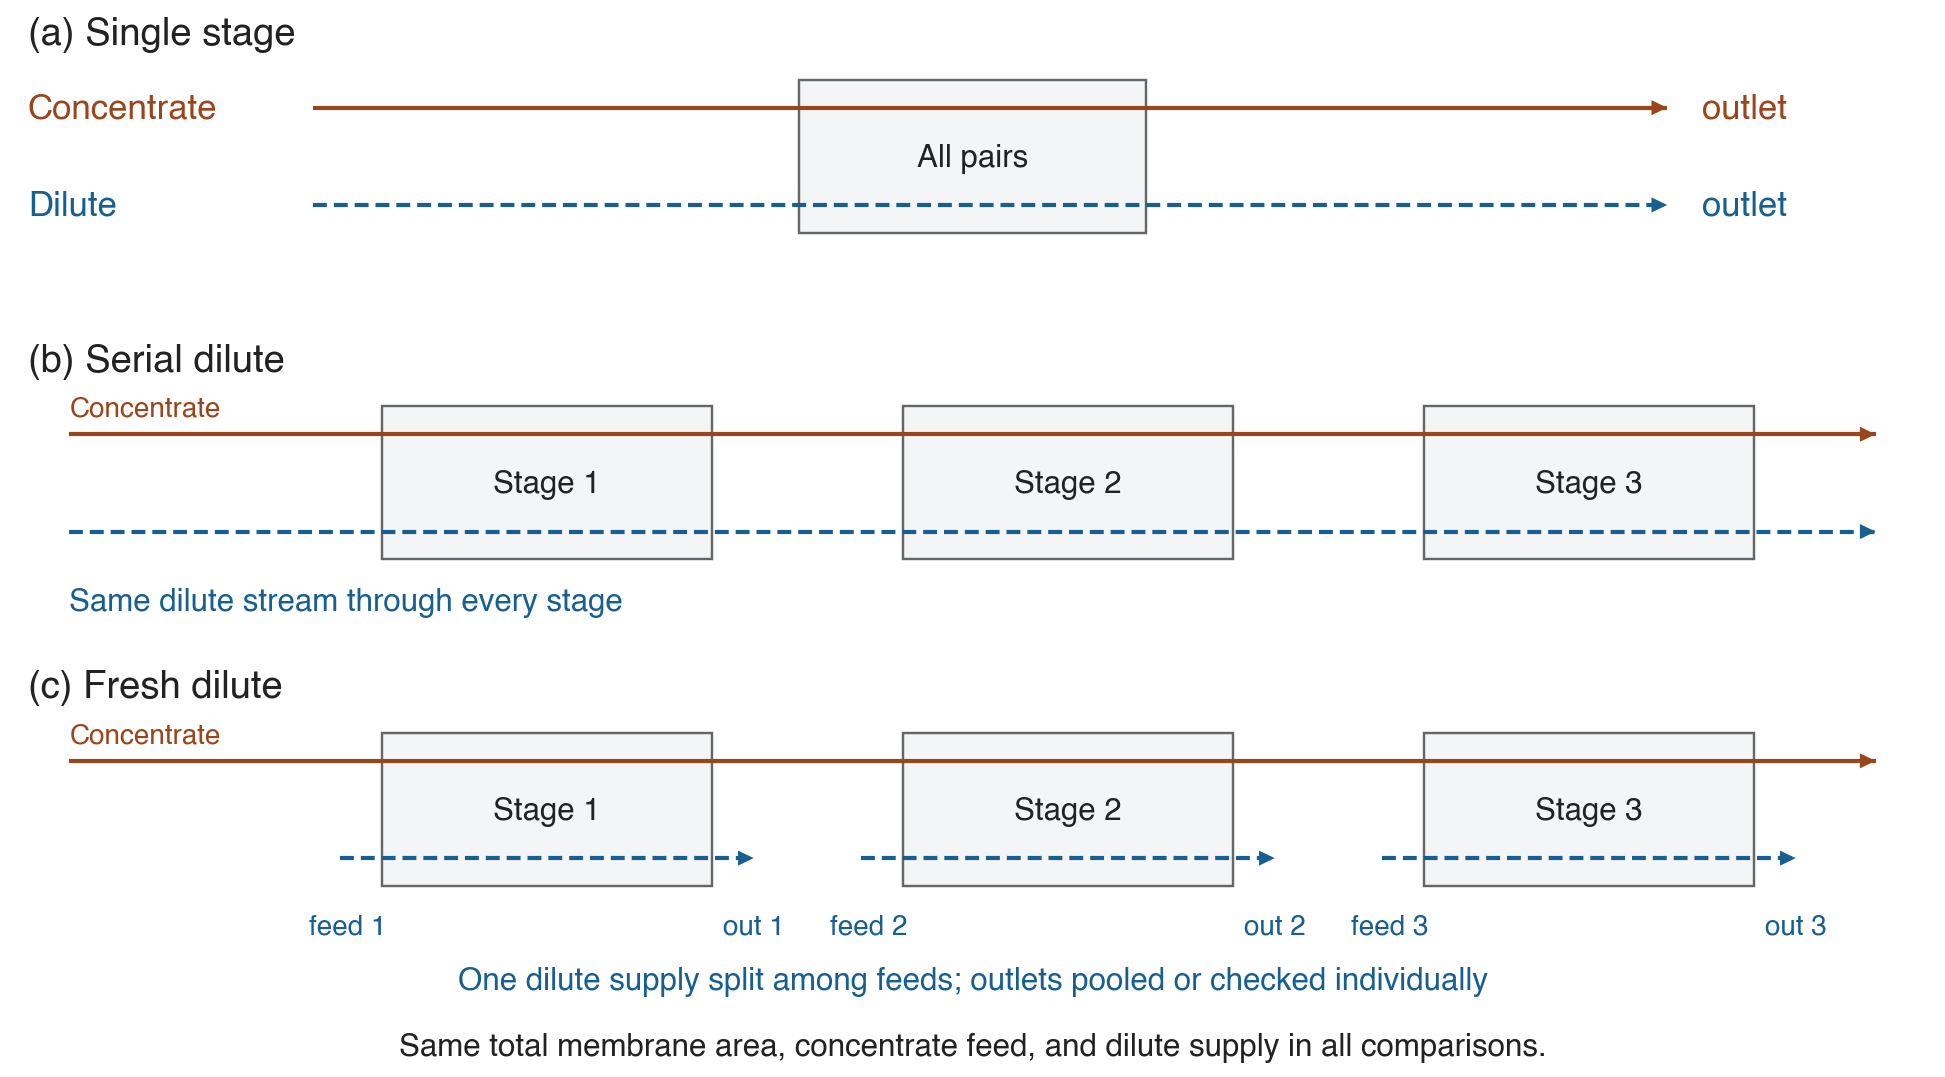

### Fig02 duty progression

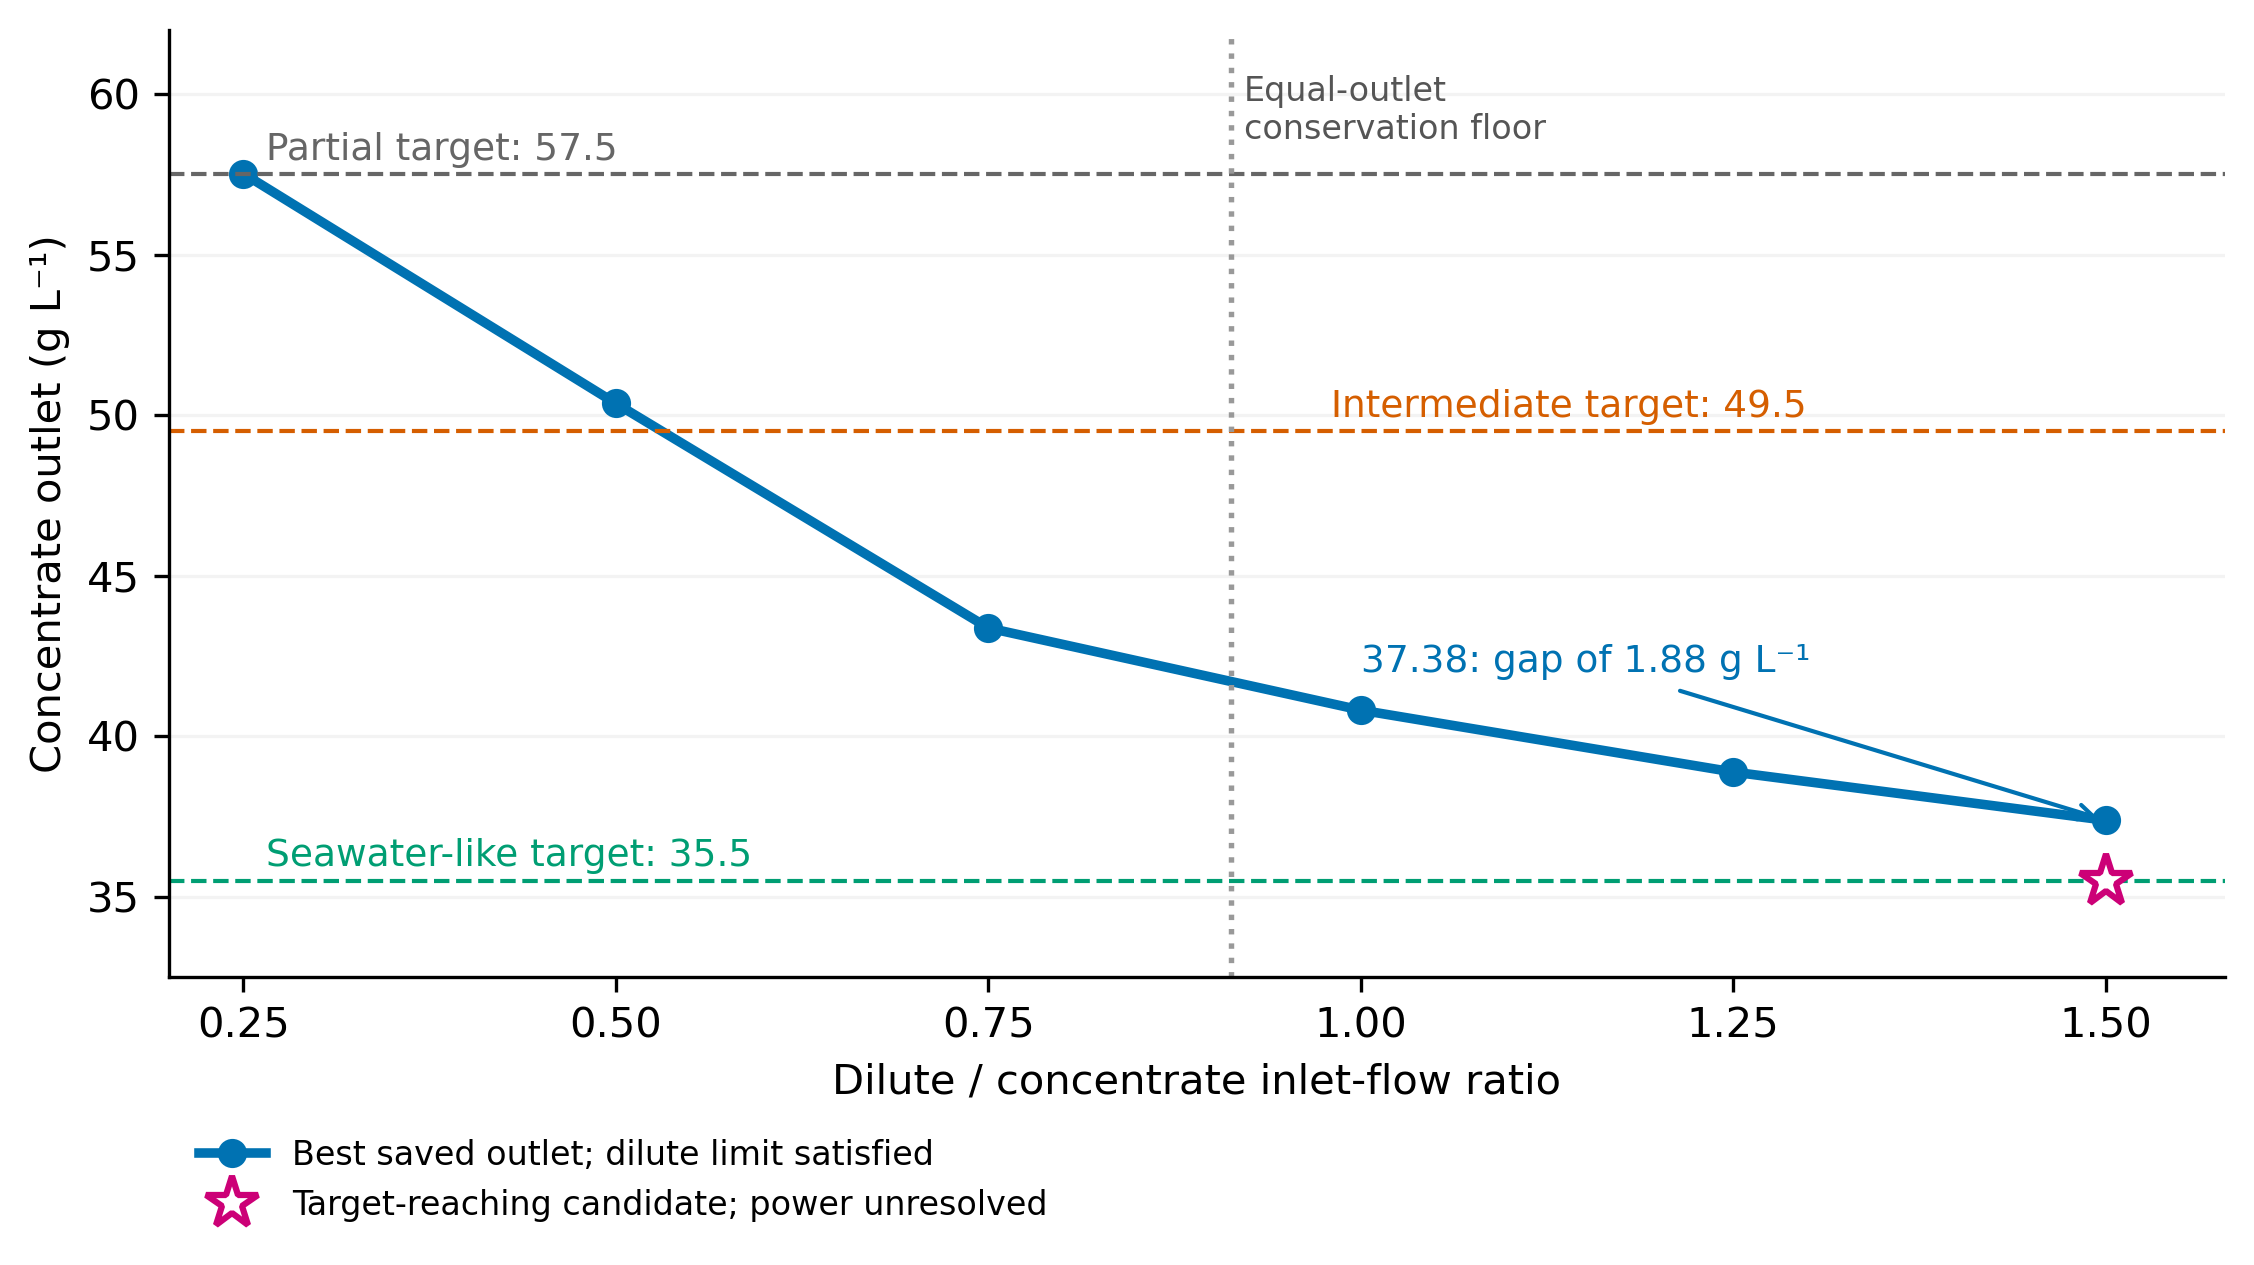

### Fig03 operating trade

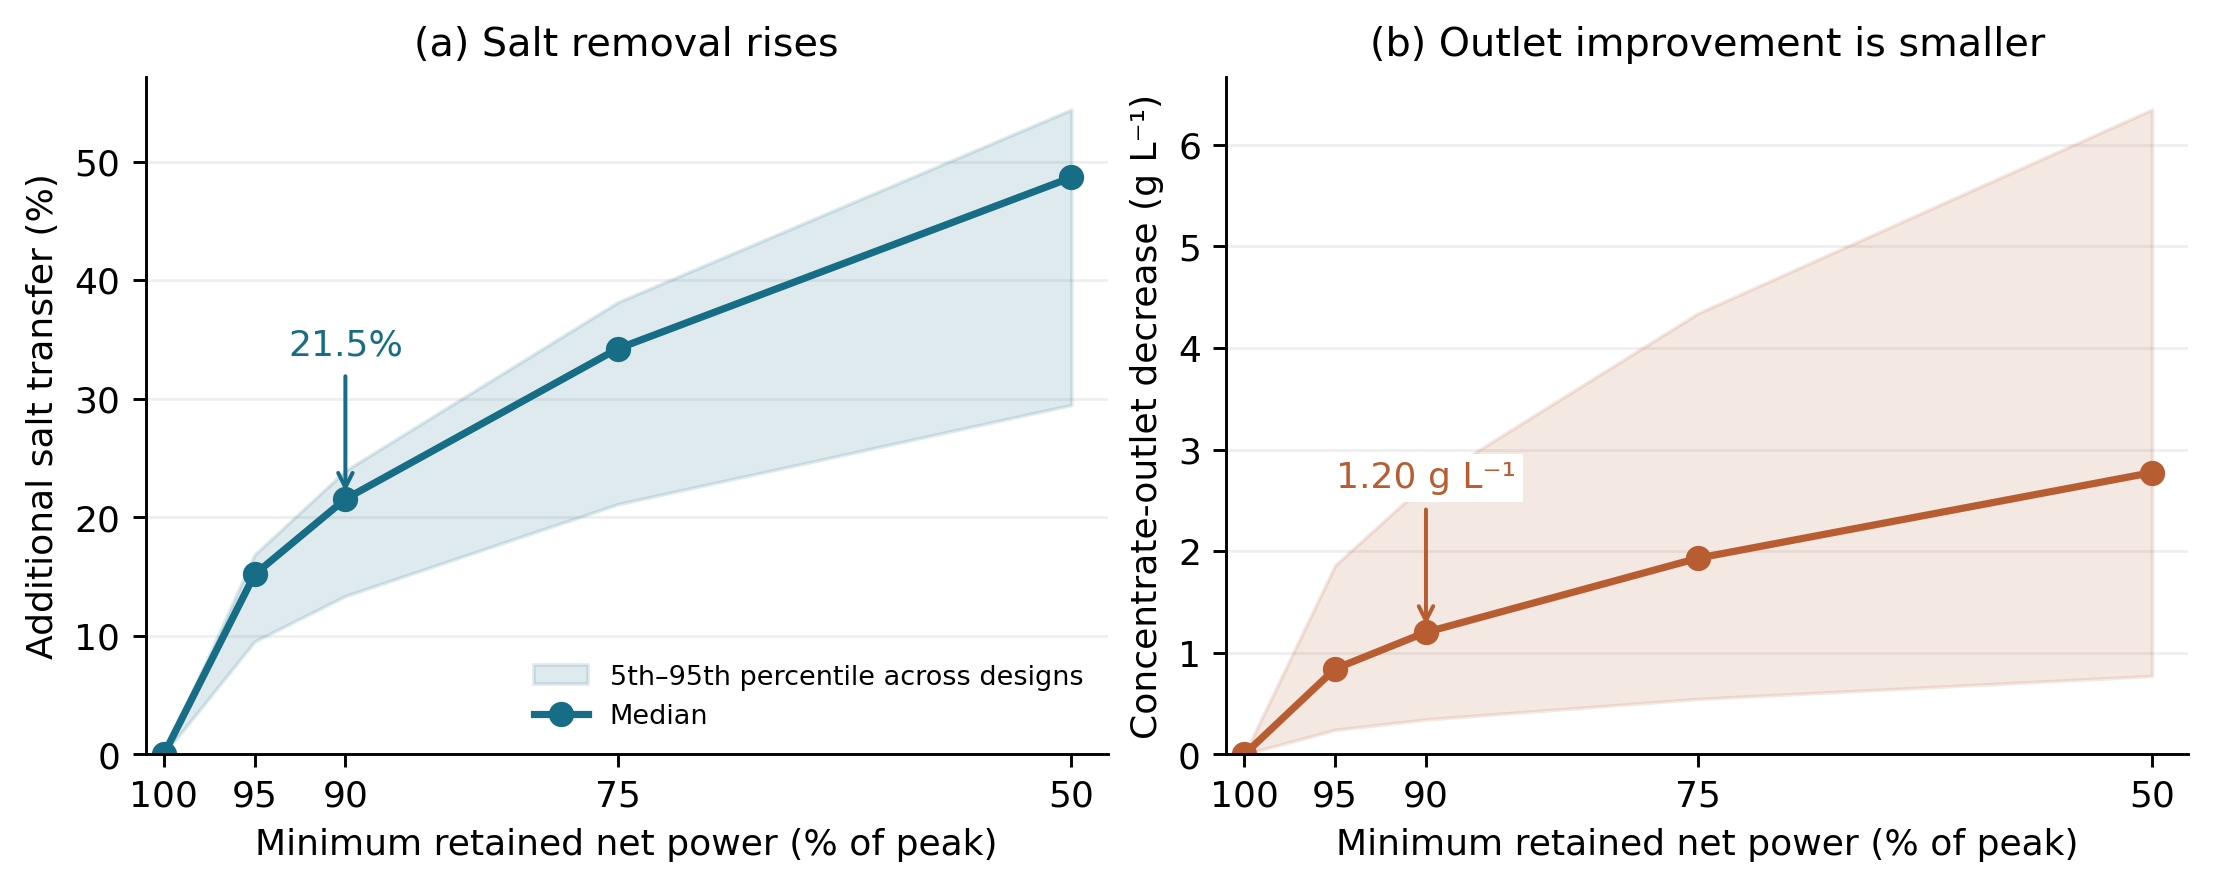

### Fig04 transport and supply

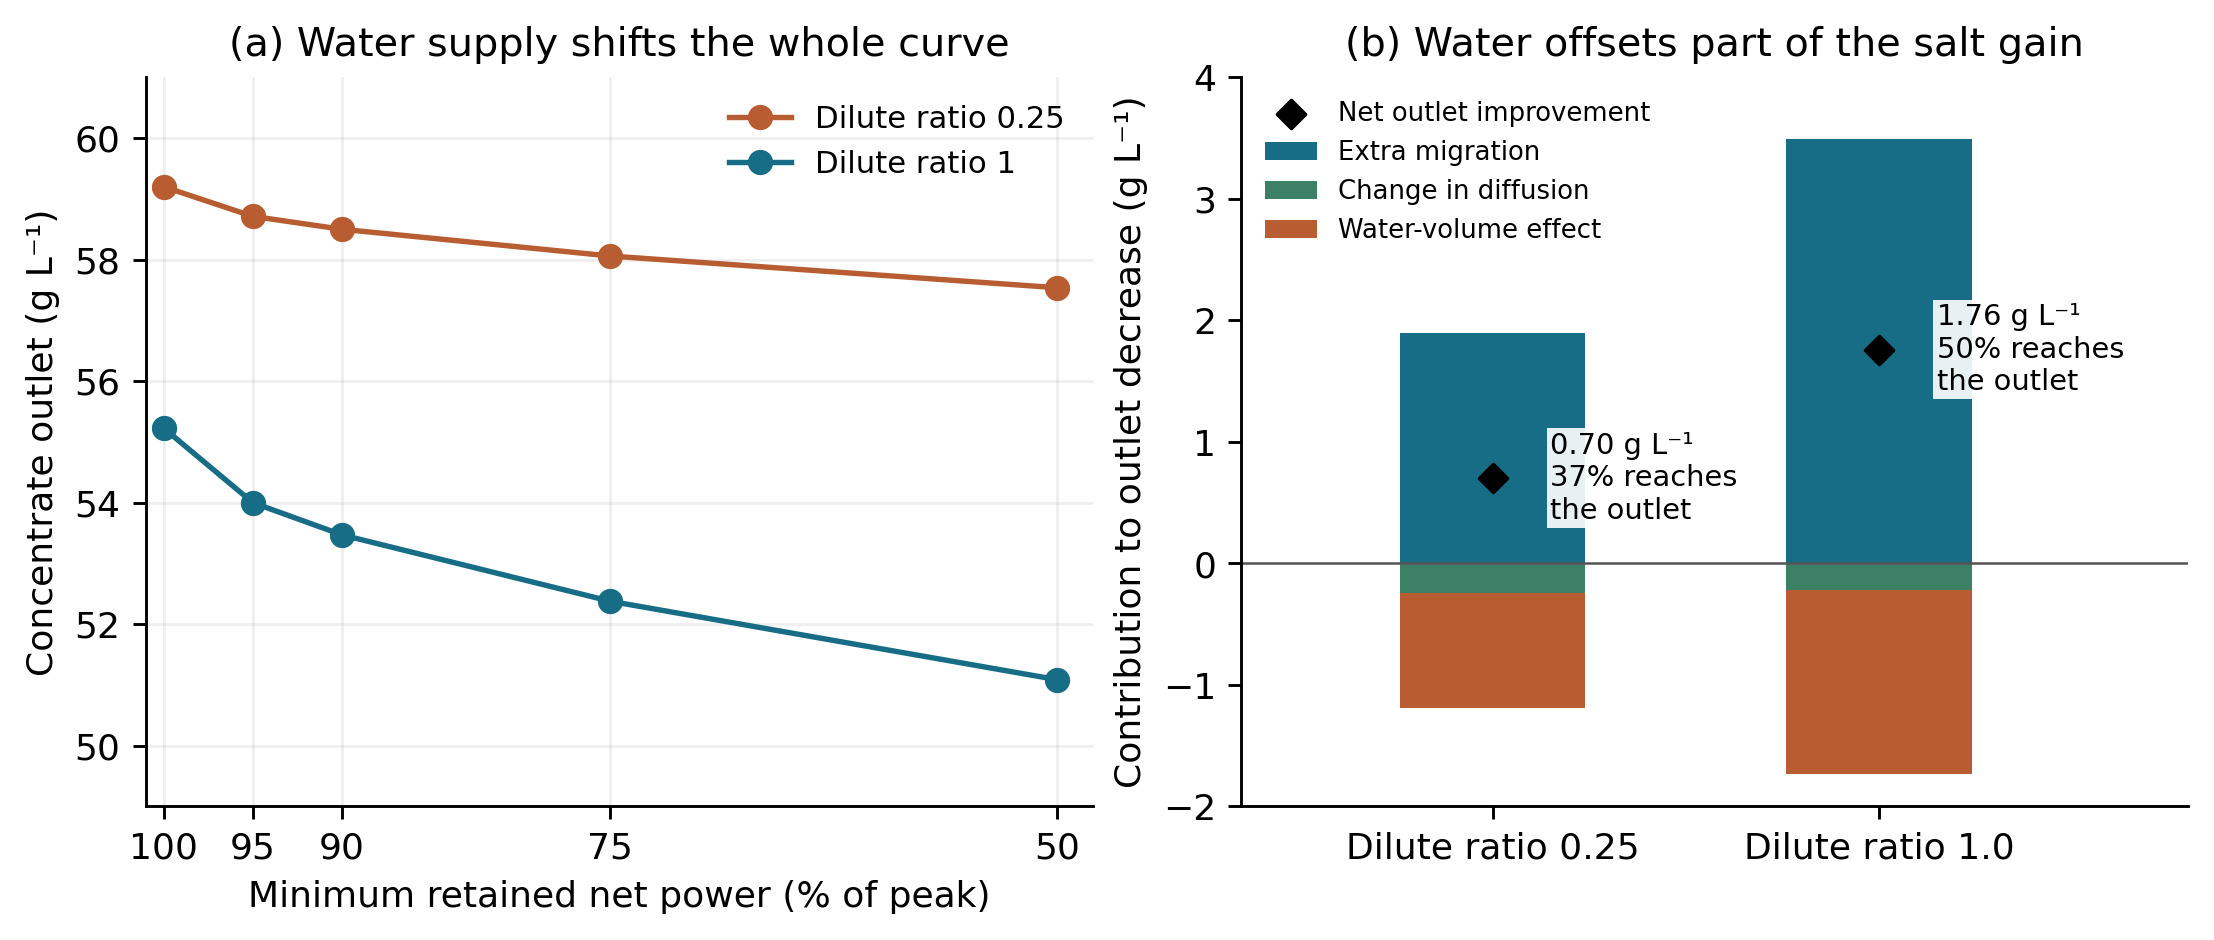

### Fig05 resource levers

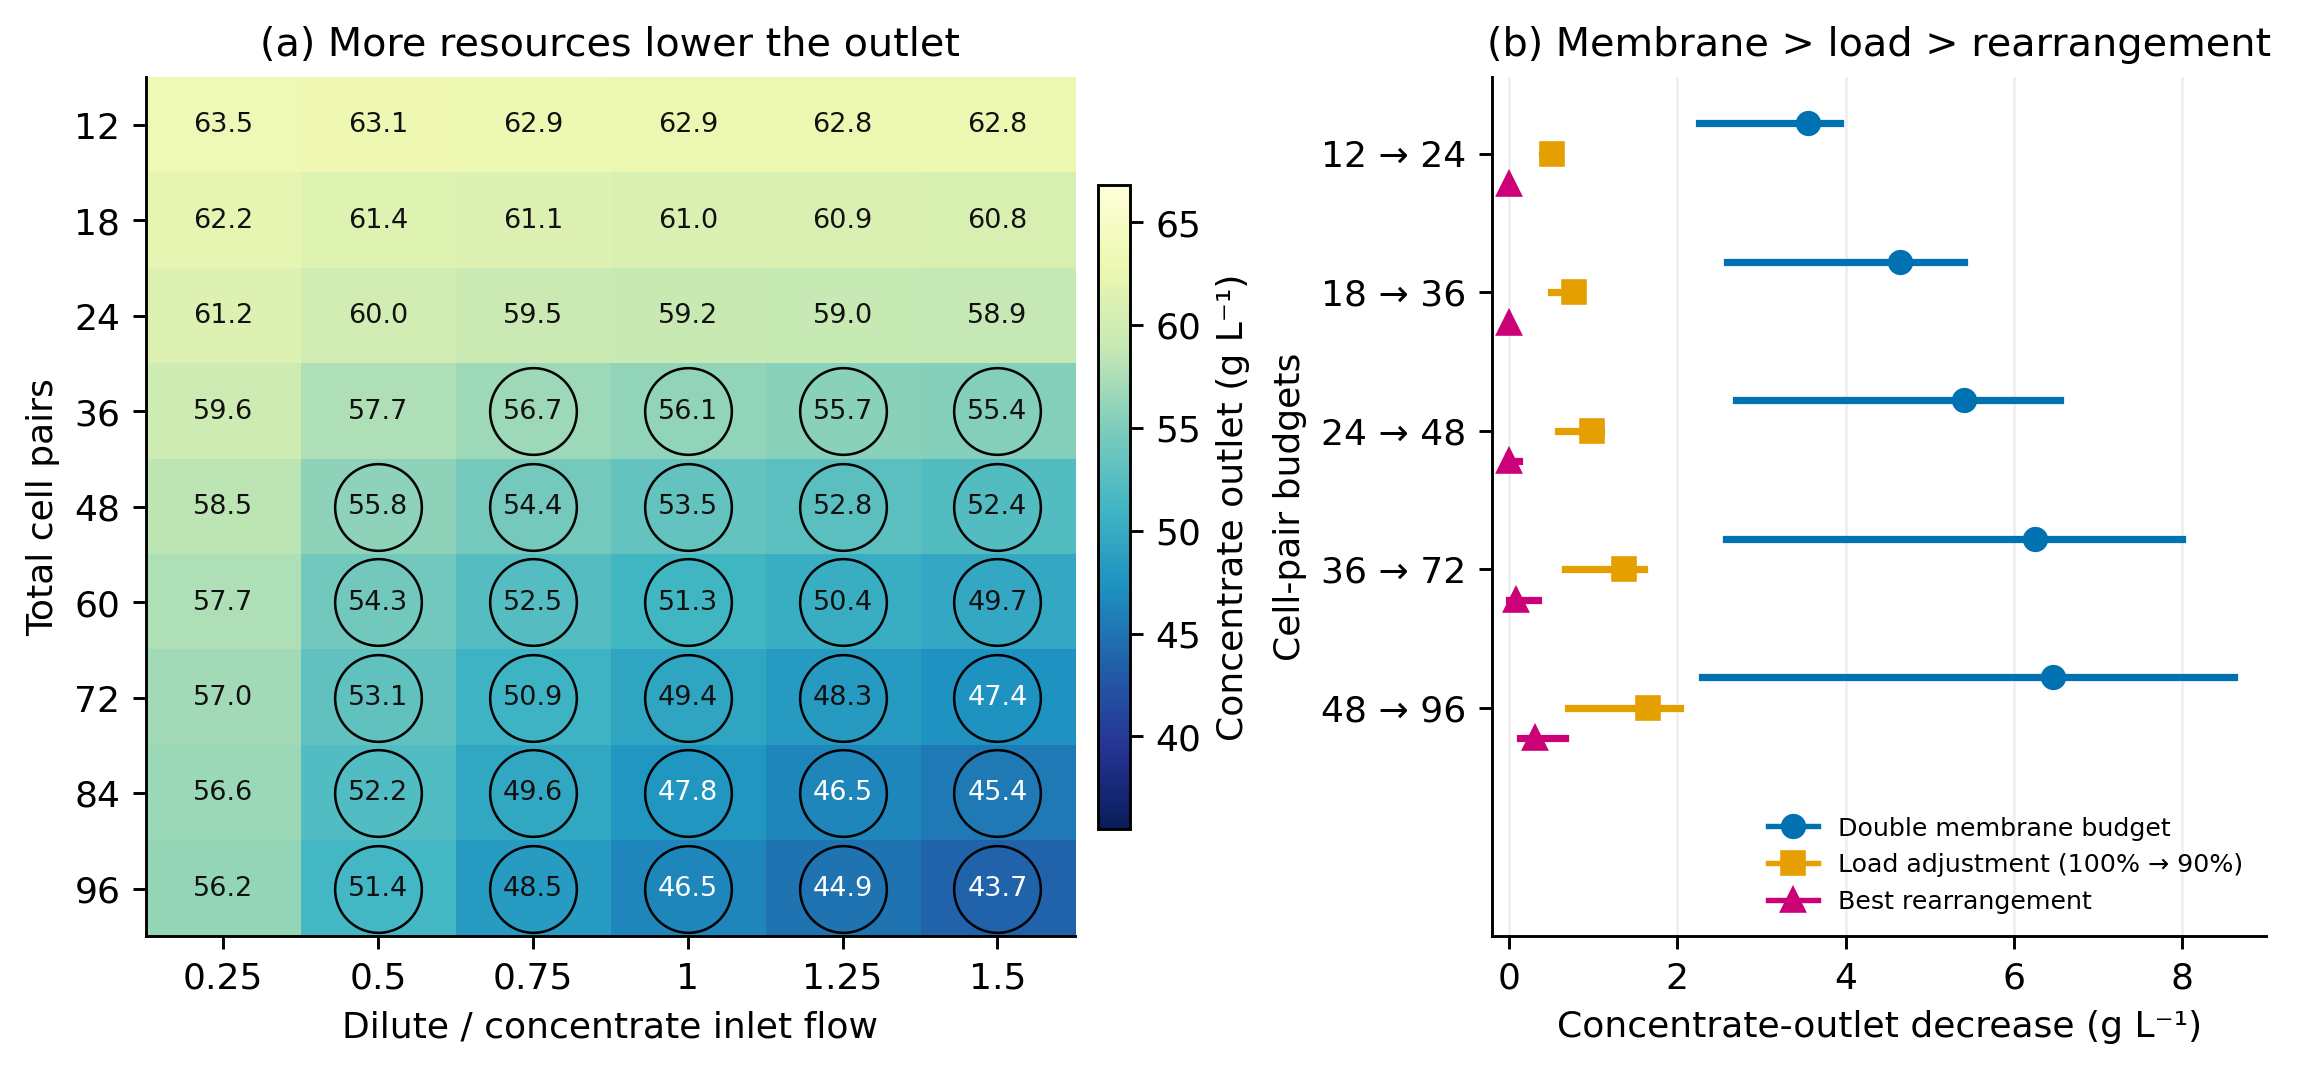

### Fig06 module hydraulics

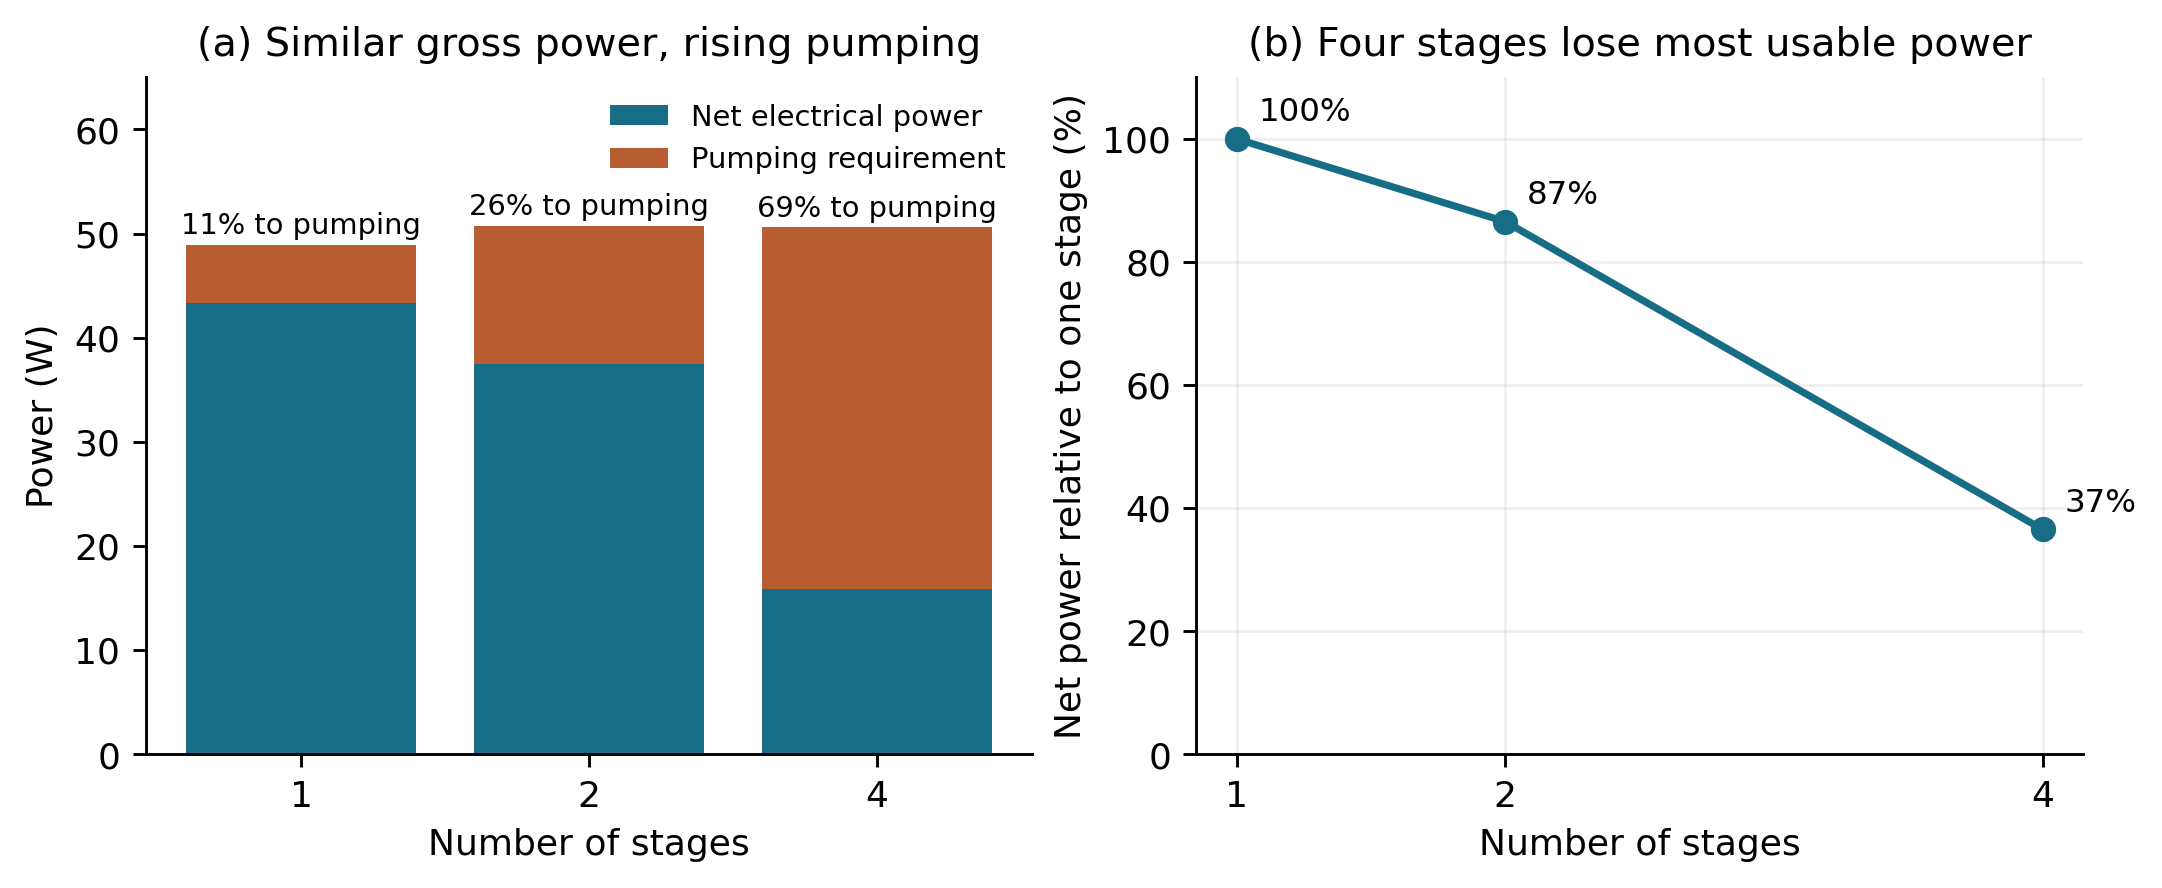

### Fig07 sizing map

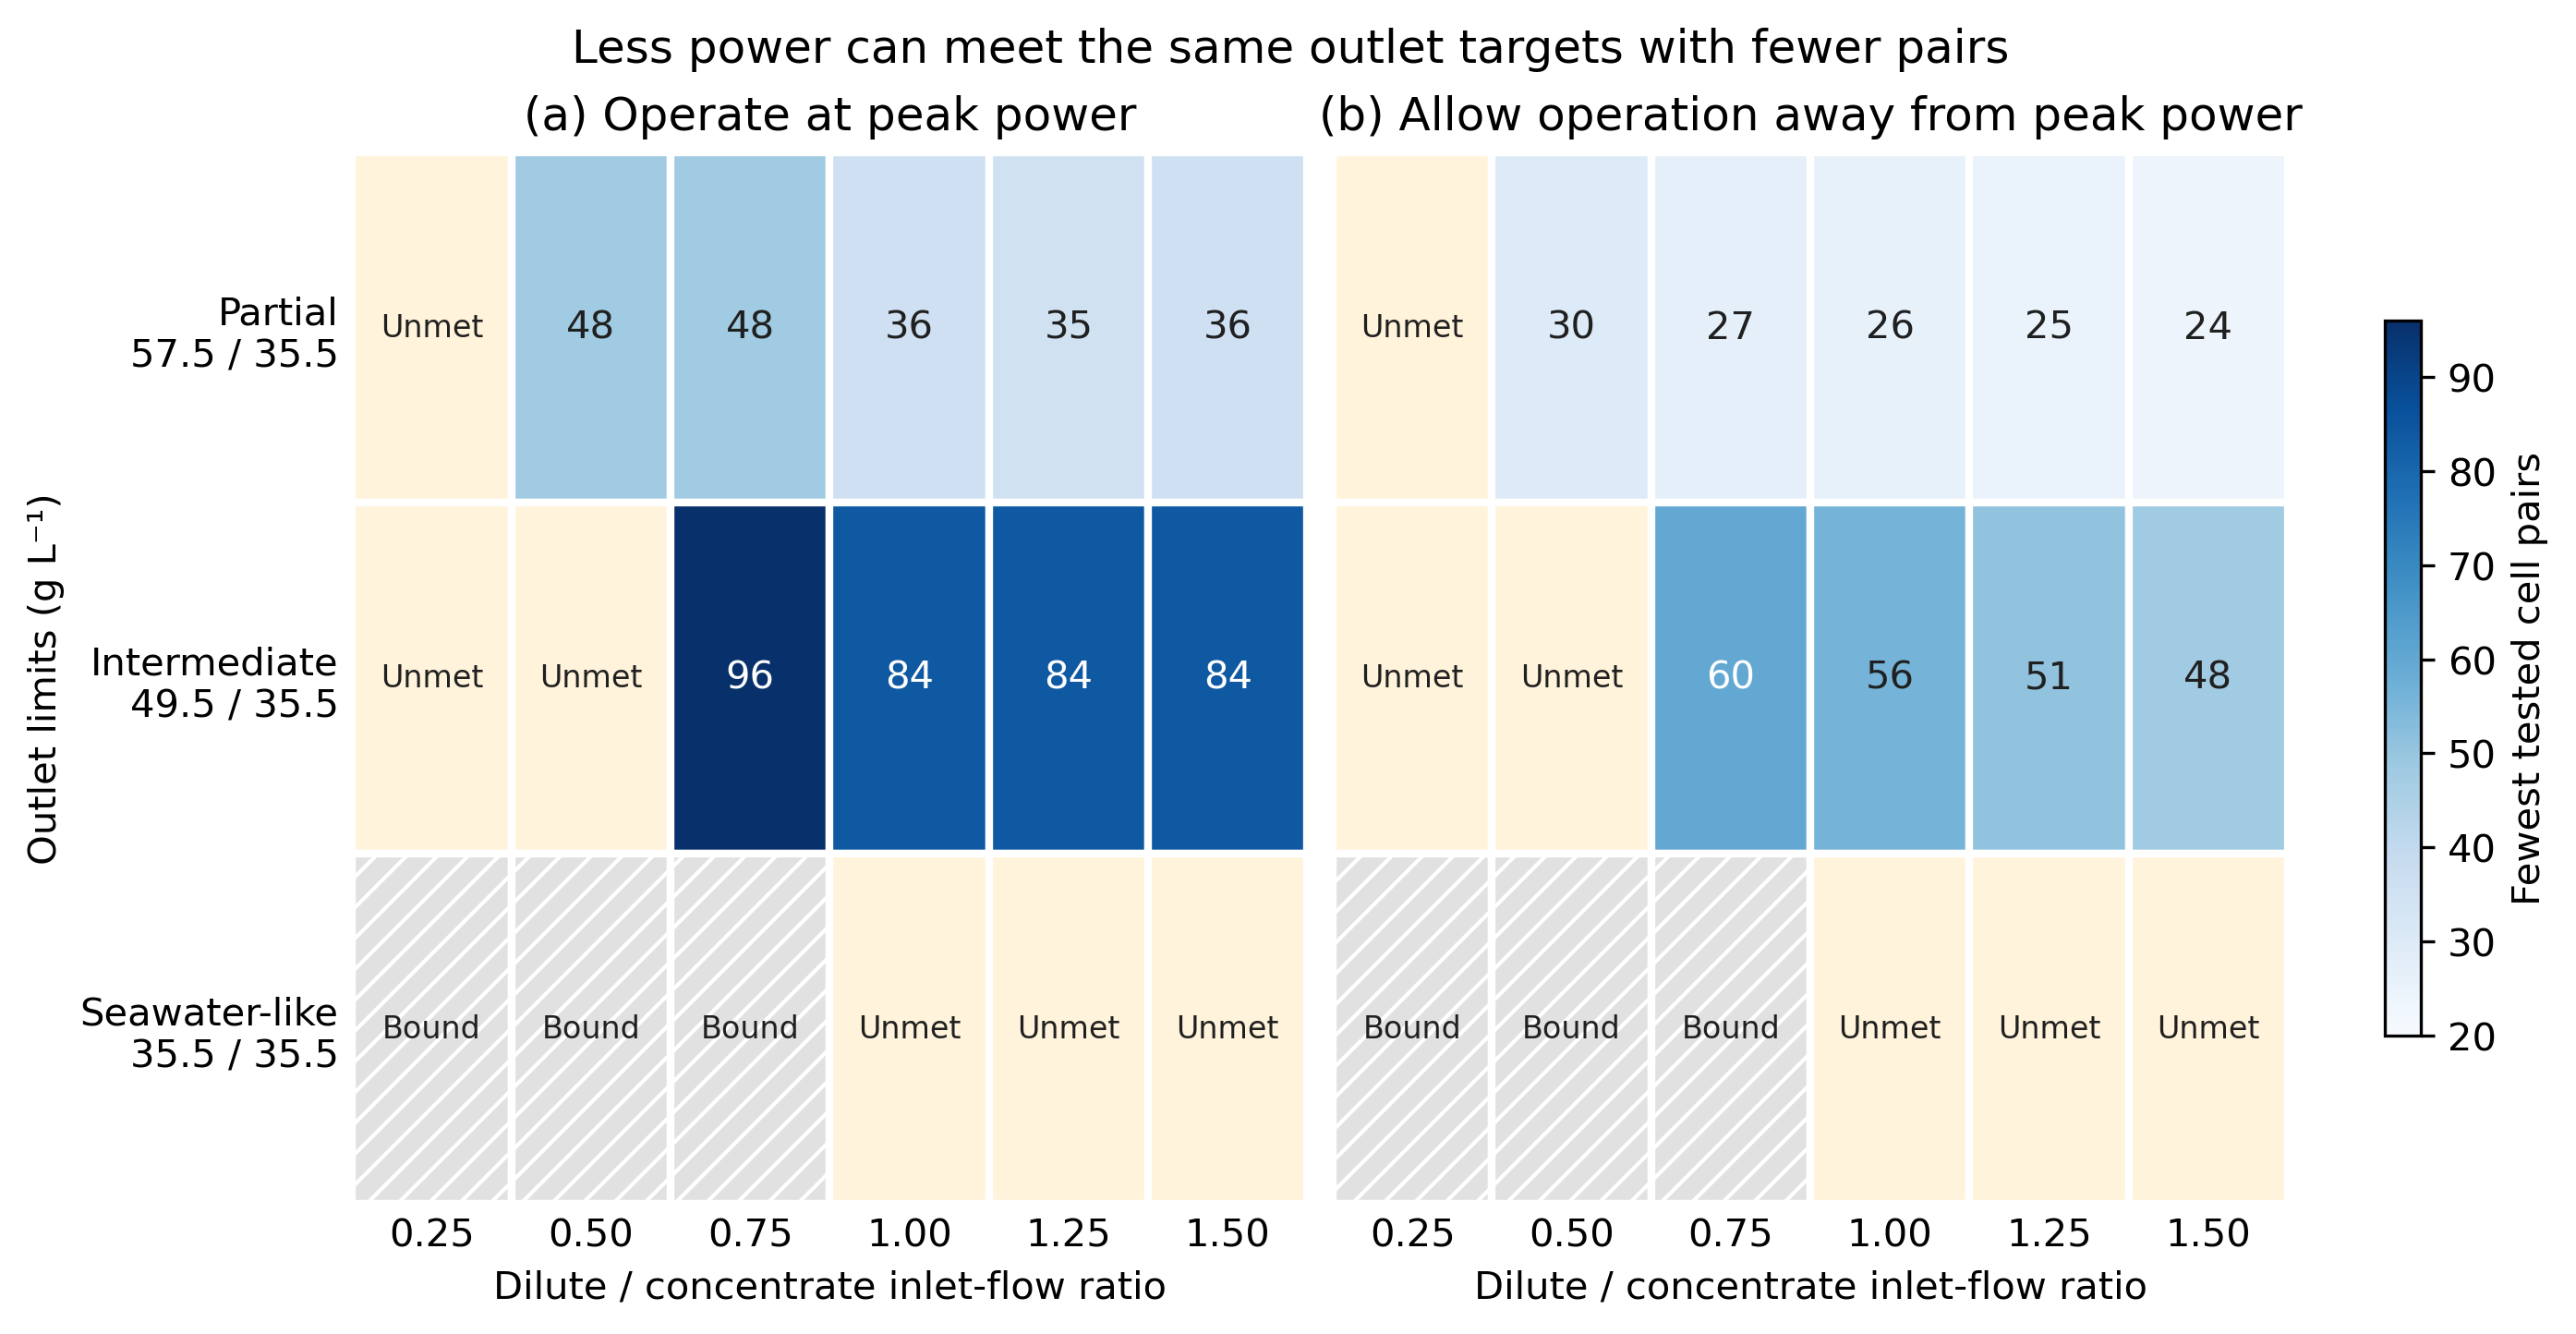

### Fig08 economic boundary

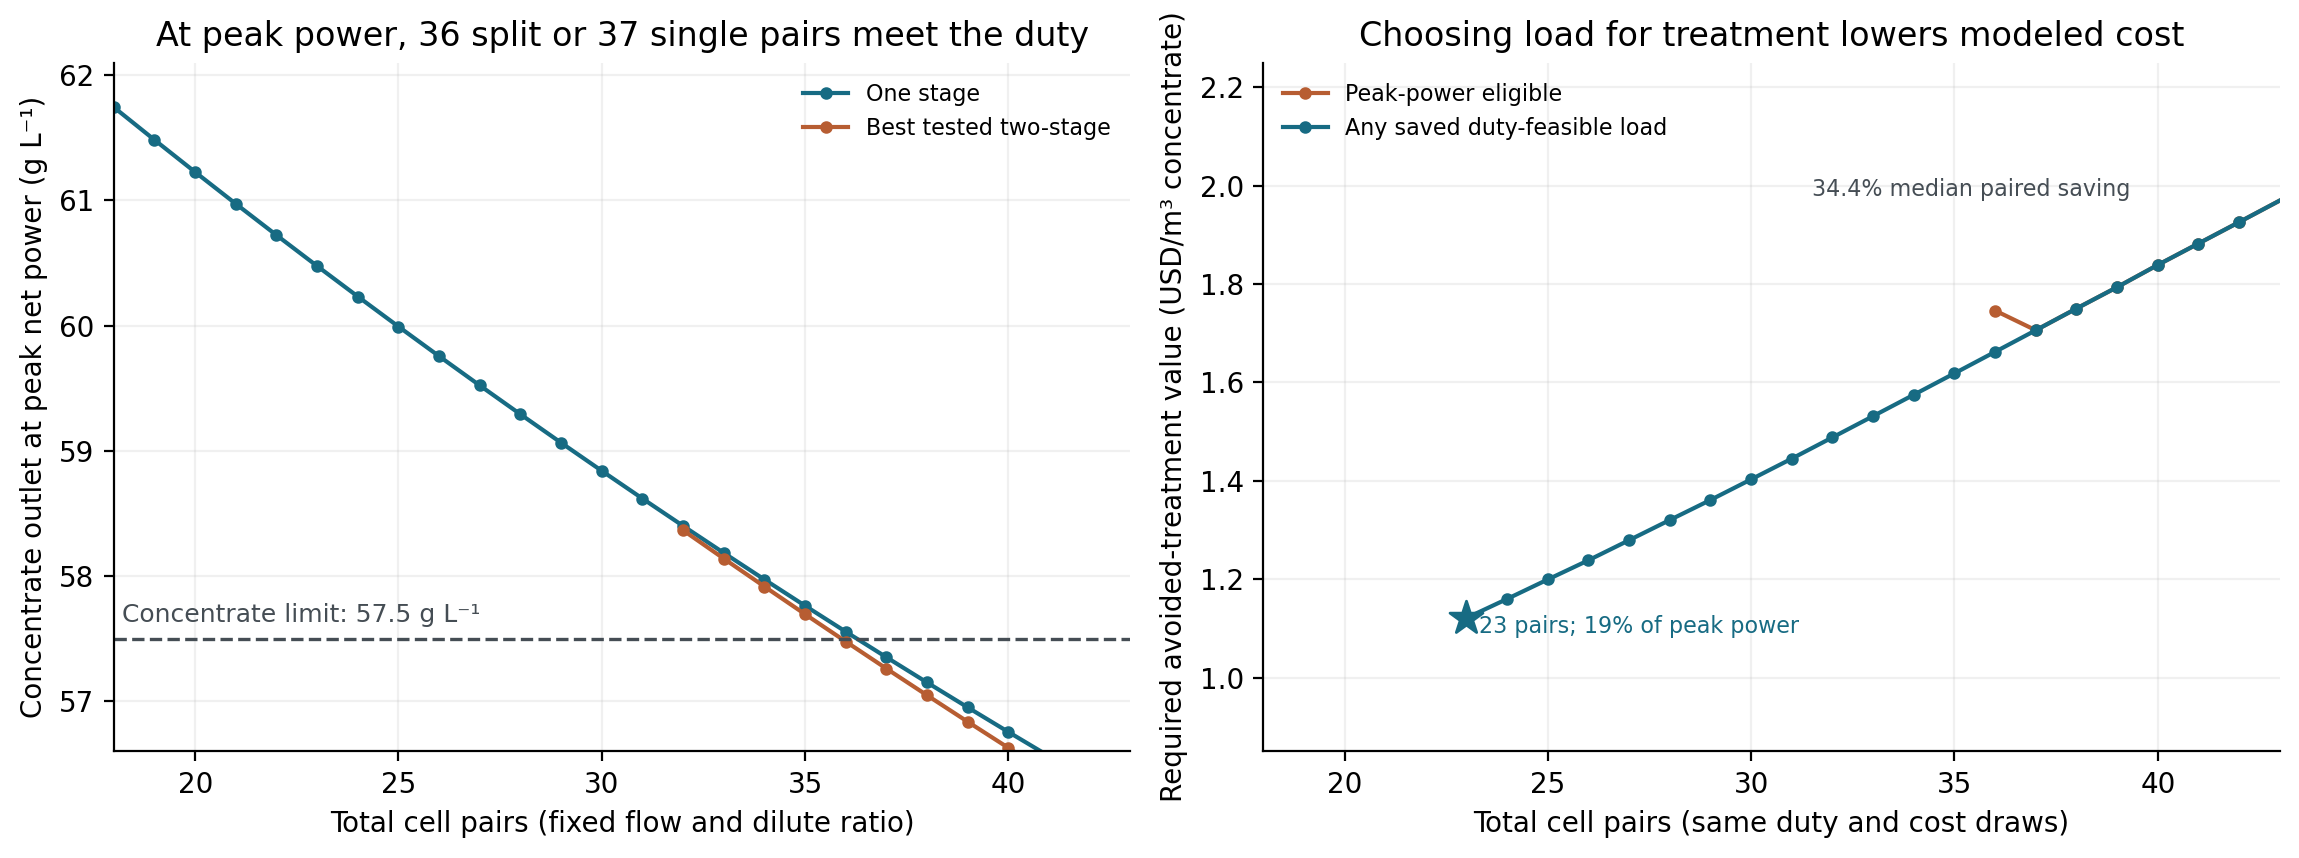

### Fig09 morris

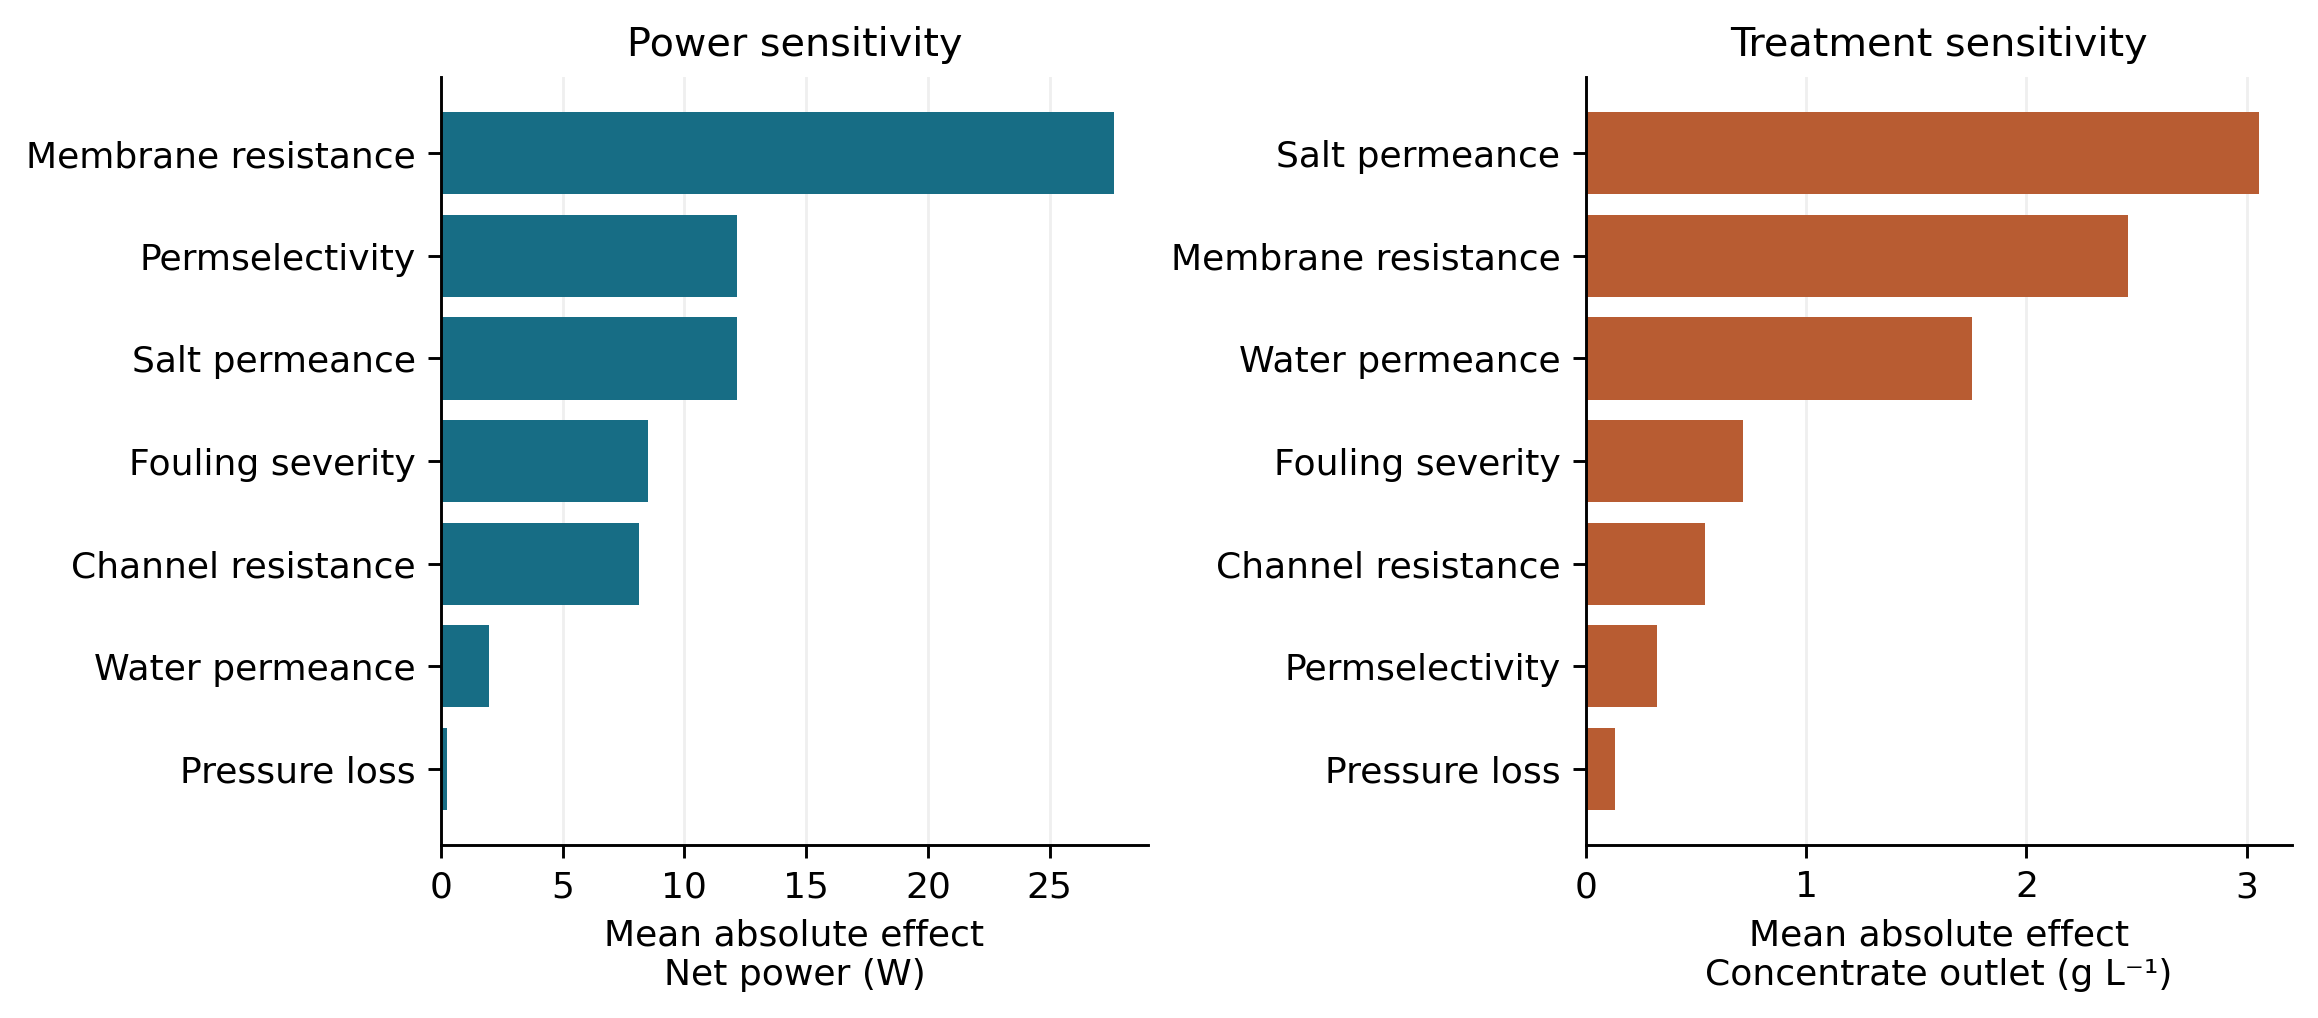

### Fig10 benchmark

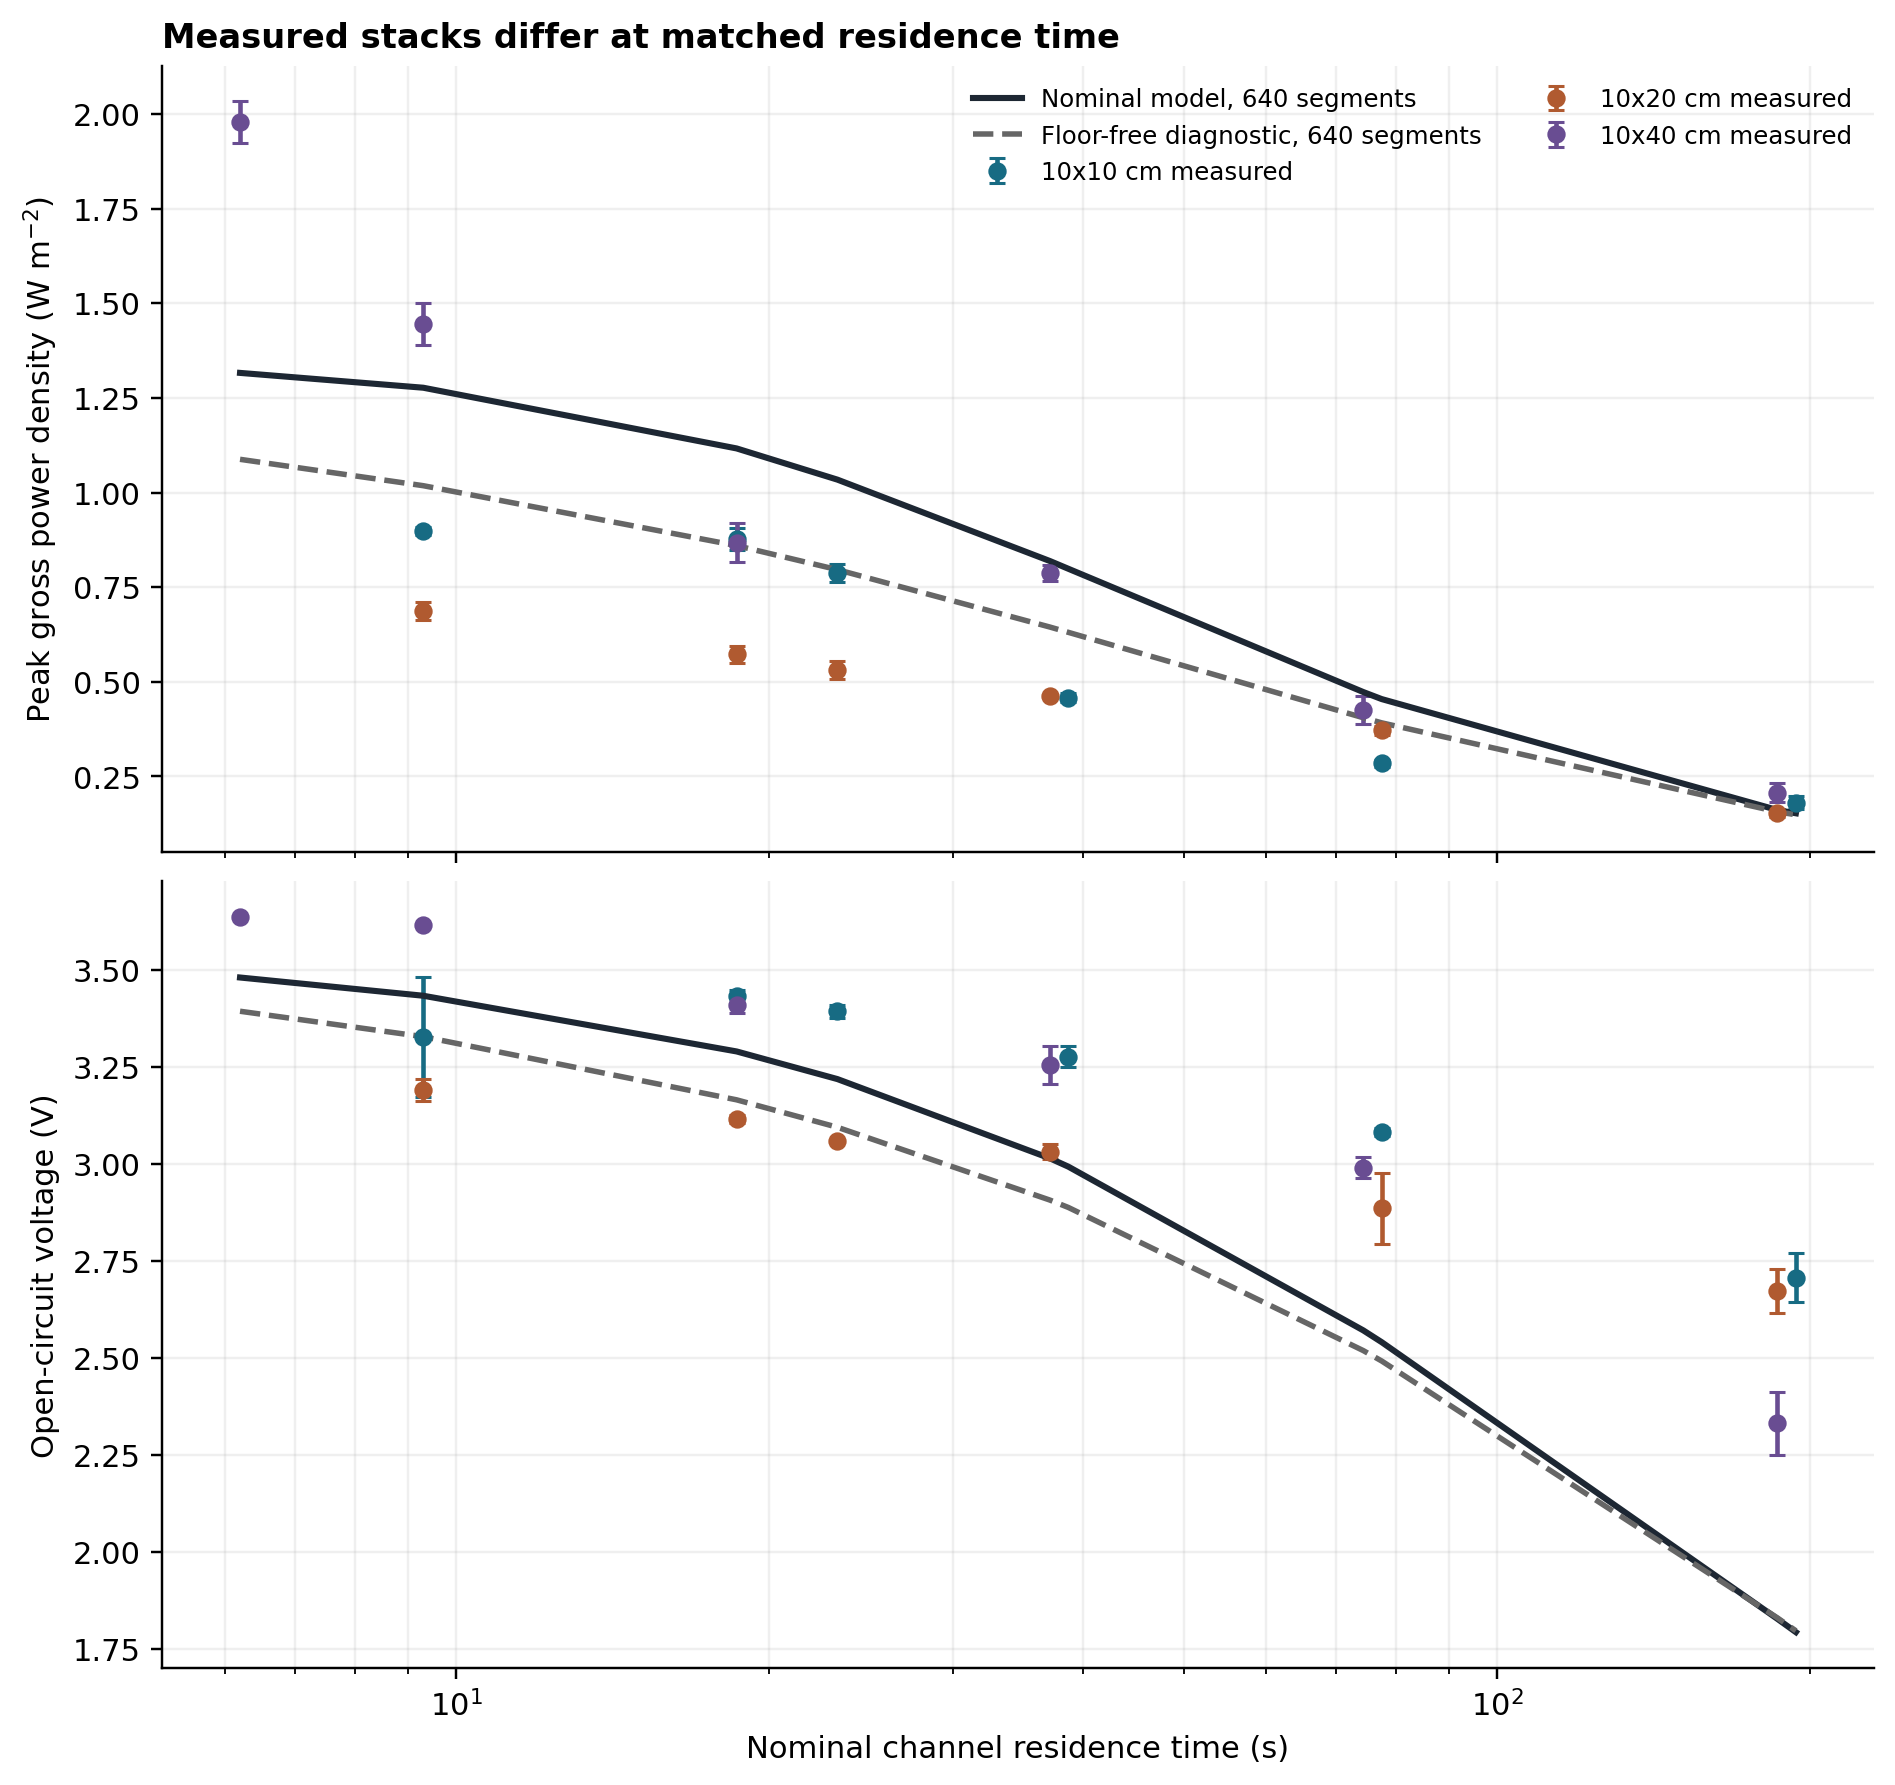

### FigS1 local law

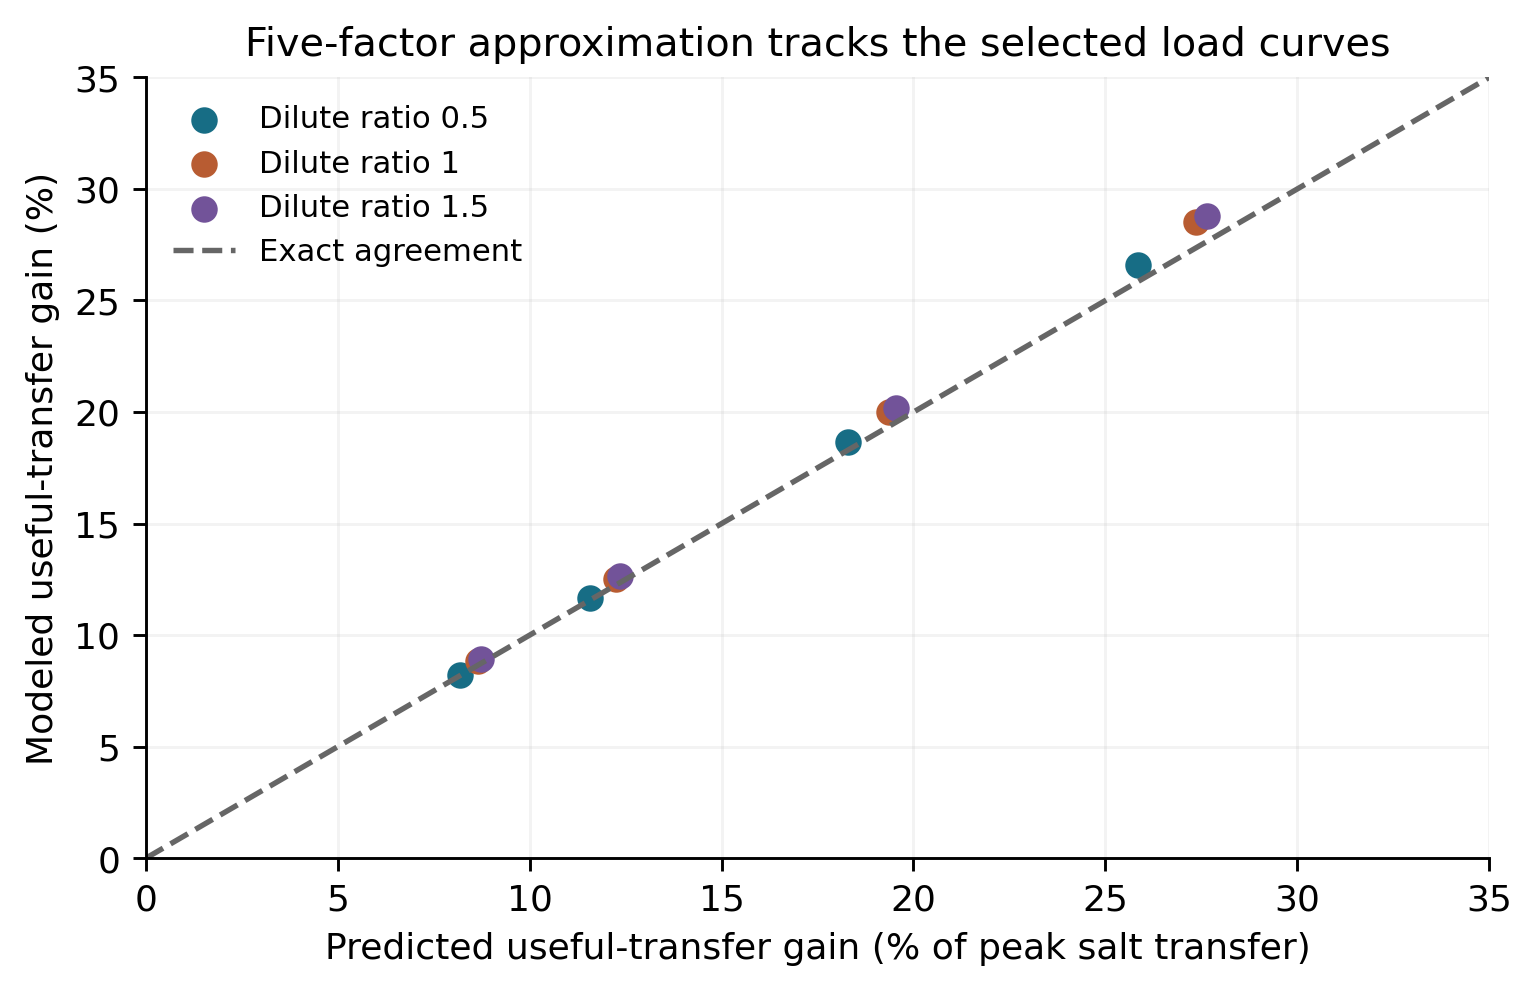

### FigS2 fouling ranking

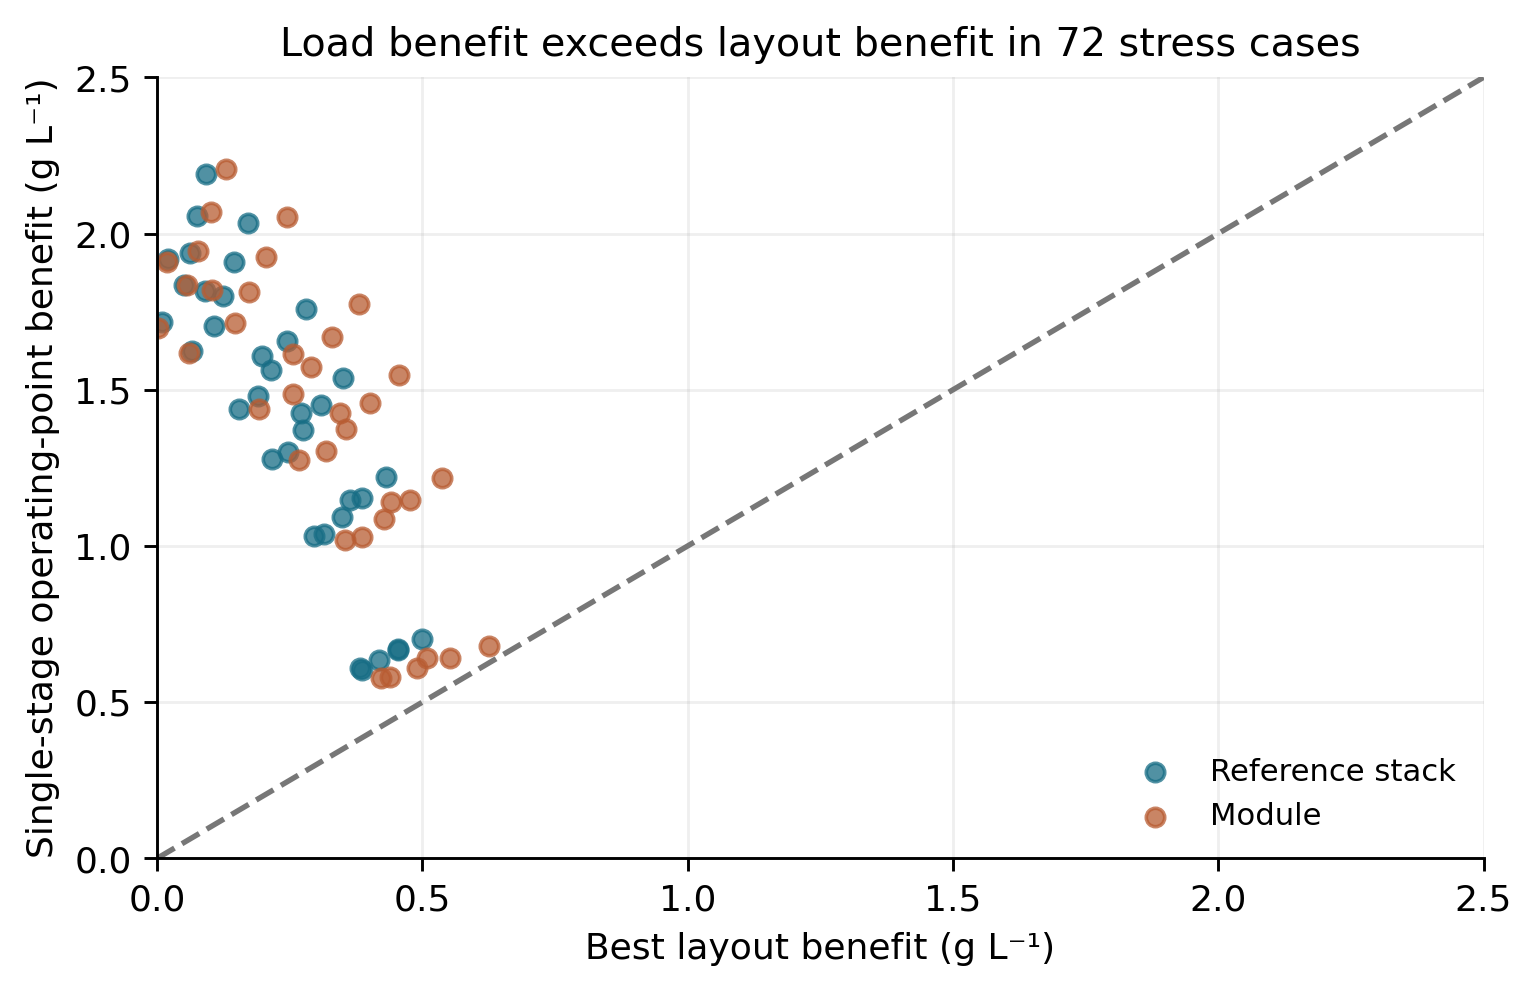

In [23]:
from IPython.display import Image, Markdown
for stem in expected:
    display(Markdown('### '+stem.replace('_',' ')))
    display(Image(filename=str(F/(stem+'.png')),width=850))